# Análise do marketplace Olist: receita por categoria e vendedor

##### Bibliotecas

In [306]:
# Importações e estilo dos gráficos
import os
import re
import html
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

##### Paletas e formatações dos Gráficos

In [307]:
# Paleta simples: rosa para destaque, cinza para comparação.
PINK = "#D63384"
PINK_MUTED = "#E9A3C7"
PINK_SOFT = "#FCE7F3"
PINK_TINT = "#FDF2F8"
INK = "#34313A"
NIGHT = "#4A4453"
SLATE = "#686270"
STEEL = "#77717D"
MIST = "#C9C4CD"
FOG = "#E8E4E9"
CLOUD = "#F5F2F5"
PAPER = "#FFFFFF"
FONT = "DejaVu Sans"
SOURCE_NOTE = "Fonte: conjunto de dados público de comércio eletrônico da Olist (Kaggle)."

mpl.rcParams.update({
    "figure.facecolor": PAPER,
    "axes.facecolor": PAPER,
    "savefig.facecolor": PAPER,
    "figure.dpi": 110,
    "savefig.dpi": 180,
    "font.family": FONT,
    "text.color": INK,
    "axes.labelcolor": SLATE,
    "axes.edgecolor": FOG,
    "xtick.color": SLATE,
    "ytick.color": SLATE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.titlepad": 10,
    "legend.frameon": False,
    "axes.grid": False,
})

##### Formatação Padrão dos textos

In [308]:
def brl(v):
    """Formata valores em reais de forma compacta."""
    if pd.isna(v):
        return "–"
    a = abs(v)
    if a >= 1e6:
        return f"R${v / 1e6:,.2f}M"
    if a >= 1e5:
        return f"R${v / 1e3:,.0f}k"
    if a >= 1e4:
        return f"R${v / 1e3:,.1f}k"
    if a >= 100:
        return f"R${v:,.0f}"
    return f"R${v:,.2f}"


def pct(v, digits=1):
    if pd.isna(v):
        return "–"
    if 0 < v < 0.001:
        return "<0.1%"
    return f"{v:.{digits}%}"


def num(v):
    return f"{v:,.0f}"


def esc(value):
    return str(value)


def hl(value):
    # Mantido para não alterar as análises;
    return str(value)


def texto(value):
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"</?(b|i|strong|em|code|span)[^>]*>", "", value, flags=re.I)
    return html.unescape(value)


def achado(*items, title="Achado"):
    print(f"**{title}**")
    for item in items:
        print(f"- {texto(item)}")
    print()


def nota(*items, title="Note"):
    print(f"{title}")
    for item in items:
        print(f"- {texto(item)}")
    print()


def question_card(tag, text):
    print(f"\n### {tag} · {text}\n")


def legend_chips():
    print("Legenda dos gráficos: rosa = destaque; cinza = comparação.\n")


def kpi_strip(items):
    # Tabela simples no lugar de cartões HTML.
    display(pd.DataFrame(items, columns=["Metric", "Value", "Context", "Highlighted"]).drop(columns="Highlighted"))


def html_table(df, caption=None, highlight=(), align=None, font_size=13):
    # Nome mantido para evitar mexer nas células analíticas; não gera HTML.
    if caption:
        print(caption)
    display(df.reset_index(drop=True))


In [309]:
def canvas( altura, titulo, subtitulo="", nrows=1, ncols=1, proporcoes_largura=None, proporcoes_altura=None,
           margem_esquerda=1.0, margem_direita=0.35, espaco_horizontal=0.25, espaco_vertical=0.35, fonte=None, margem_rodape=None):
    """Cria uma figura com título, subtítulo opcional e fonte."""

    # Cria a figura com largura fixa de 10 polegadas
    fig = plt.figure(figsize=(10, altura))

    # Divide a figura em uma grade para posicionar os gráficos
    grade = fig.add_gridspec( nrows, ncols, left=max(0.10, margem_esquerda / 10), right=1 - margem_direita / 10,
        top=0.76 if subtitulo else 0.90, bottom=max(0.08, (margem_rodape or 0.35) / altura), wspace=espaco_horizontal,
        hspace=espaco_vertical, width_ratios=proporcoes_largura, height_ratios=proporcoes_altura
    )

    # Adiciona o título principal
    fig.text( 0.08, 0.96, titulo, fontsize=15, fontweight="bold", color=INK, ha="left", va="top")

    # Adiciona o subtítulo, se informado
    if subtitulo:
        fig.text( 0.08, 0.91, subtitulo, fontsize=9, color=SLATE, ha="left", va="top", linespacing=1.35)

    # Adiciona a fonte dos dados no rodapé
    fig.text(
        0.08, 0.025,
        fonte or SOURCE_NOTE,
        fontsize=8,
        color=STEEL,
        ha="left",
        va="bottom"
    )

    # Retorna a figura e a grade para inserir os gráficos
    return fig, grade


def ranking_de_barras(ax, rotulos, valores, textos_valores, destaques=(0,), mostrar_rotulos=True, limite_x=None, margem=0.32, altura_barra=0.62):
    """Cria um ranking de barras horizontais com destaques em rosa."""

    # Define a quantidade de barras e suas posições
    quantidade = len(valores)
    posicoes = np.arange(quantidade)

    # Desenha as barras, destacando os itens selecionados
    ax.barh(
        posicoes,
        valores,
        height=altura_barra,
        color=[
            PINK if i in destaques else MIST
            for i in range(quantidade)
        ],
        zorder=3
    )

    # Define o limite do eixo X, deixando espaço para os valores
    maior_valor = (
        limite_x
        if limite_x is not None
        else max(valores) * (1 + margem)
    )
    ax.set_xlim(0, maior_valor)

    # Organiza as barras de cima para baixo
    ax.set_ylim(quantidade - 0.45, -0.85)

    # Configura os rótulos do eixo Y
    ax.set_yticks(posicoes)
    ax.set_yticklabels(rotulos if mostrar_rotulos else [])
    ax.tick_params(axis="y", length=0, pad=6)

    # Oculta o eixo X para deixar o gráfico mais limpo
    ax.xaxis.set_visible(False)

    # Escreve o valor de cada barra ao lado dela
    for i, (posicao, valor, texto) in enumerate(
        zip(posicoes, valores, textos_valores)
    ):
        ax.text(
            valor + maior_valor * 0.012,
            posicao,
            texto,
            va="center",
            ha="left",
            fontsize=9,
            color=INK,
            fontweight="bold" if i in destaques else "normal"
        )

    return ax


def adicionar_legenda( ax, itens, x=0.0, y=1.0, espacamento_vertical=0.085, tamanho_fonte=9):
    """Adiciona uma legenda personalizada com cores e rótulos."""

    # Percorre os itens da legenda: cada um contém cor e rótulo
    for i, (cor, rotulo) in enumerate(itens):

        # Desenha o retângulo que representa a cor
        ax.add_patch(
            plt.Rectangle(
                (x, y - i * espacamento_vertical - 0.03),
                0.035,
                0.045,
                transform=ax.transAxes,
                color=cor,
                clip_on=False
            )
        )

        # Escreve o texto ao lado do retângulo
        ax.text(
            x + 0.055,
            y - i * espacamento_vertical - 0.008,
            rotulo,
            transform=ax.transAxes,
            va="center",
            fontsize=tamanho_fonte,
            color=INK
        )


def show(fig, nome):
    """Salva a figura, se habilitado, exibe e fecha o gráfico."""

    # Salva a figura em PNG, caso a opção esteja ativada
    if SAVE_FIGURES:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            FIG_DIR / f"{nome}.png",
            dpi=180,
            bbox_inches="tight"
        )

    # Exibe o gráfico e libera os recursos da figura
    plt.show()
    plt.close(fig)

> **Pergunta principal:** quais categorias de produtos e quais vendedores geraram a maior e a menor receita com produtos nos 12 meses mais recentes do conjunto de dados público da Olist? E quanto essa resposta muda conforme as decisões metodológicas?

Este notebook responde a três perguntas de negócio sobre um marketplace brasileiro. Também documenta quanto cada resposta depende das definições adotadas: o que conta como receita, quais pedidos entram na análise e quais 12 meses são considerados.

**Conteúdo**

1. Contexto de negócio e objetivos
2. Visão geral dos dados e qualidade
3. Limpeza e preparação dos dados
4. Análise exploratória
5. Perguntas de negócio e principais resultados
6. Conclusões, limitações e próximos passos

**Como interpretar a análise:** os resultados são descritivos, não causais. Os números e destaques são calculados a partir dos dados quando o notebook é executado; as interpretações e ressalvas ficam separadas dos resultados observados.

## 1. Contexto de negócio e objetivos

**Contexto.** A Olist conecta pequenos lojistas a grandes marketplaces no Brasil. Quando uma pessoa compra um produto, o vendedor é notificado e fica responsável pelo pedido. A Olist publicou no Kaggle um recorte com cerca de 100 mil pedidos realizados entre 2016 e 2018, distribuídos em tabelas relacionadas: pedidos, itens, pagamentos, avaliações, clientes, vendedores e produtos.

**Perguntas de negócio.** A análise responde a três perguntas sobre os 12 meses mais recentes dos dados:

| Nº | Pergunta | Seção |
|---|---|---|
| Q1 | Quais categorias de produtos têm a **maior e a menor receita**? | 5.1 |
| Q2 | Quais são os **10 vendedores com maior receita**? | 5.2 |
| Q3 | Quais são os **10 vendedores com menor receita**, e o que isso realmente significa? | 5.3 |

Também queremos tornar explícitas as definições usadas (receita, pedido e período) e testar quanto os rankings mudam quando essas definições são alteradas (Seção 5.4).

**Definições usadas no notebook**

| Termo | Definição |
|---|---|
| **Receita com produtos** | Soma de `price` nos pedidos entregues. Representa o valor dos produtos vendidos, **sem frete**. É a métrica principal. |
| **Frete** | Soma de `freight_value` dos mesmos itens (valor de envio cobrado do cliente). |
| **Total dos itens** | Receita com produtos + frete. Usado apenas quando indicado. |
| **Valor do pagamento** | `payment_value` da tabela de pagamentos. Usado apenas para *validar* os totais dos itens, nunca como receita. |
| **Pedido por vendedor** | Itens de um pedido atendidos por um vendedor. O valor médio por pedido de cada vendedor é a receita com produtos dividida pelo número de pedidos atendidos por ele. |
| **Período de análise** | Os últimos 12 meses-calendário completos que contêm compras entregues, determinados a partir dos dados na Seção 3. |


> **Escopo:** a receita com produtos representa o valor das vendas dos lojistas no marketplace. **Não é a receita da própria Olist**, pois os dados não informam comissões ou taxas. Os valores monetários estão em reais (R$).


**Como ler os gráficos:** a paleta é intencionalmente simples: rosa destaca o resultado principal e cinza serve de comparação.

### Configurações e parâmetros

Os caminhos e parâmetros da análise ficam reunidos em um único lugar. Os gráficos usam uma paleta consistente: rosa para destacar o resultado principal e cinza para comparação.

In [310]:
# Caminhos e parâmetros da análise ----------------------------------------------
DATA_DIR = Path(os.environ.get("OLIST_DATA_DIR", "dataset"))   # usando a biblioteca path para lidar com os caminhos dos arquivos do Olist
WINDOW_MONTHS = 12        # Janela de análise
TOP_N = 10                # Tamanho dos rankings

# Exportar todos os gráficos para a página correta
SAVE_FIGURES = True     
FIG_DIR = Path("imagens")

## 2. Visão geral dos dados e qualidade

### 2.1 Fonte e estrutura

**Fonte:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), publicado pela Olist no Kaggle. Os arquivos brutos **não são redistribuídos** neste projeto. Confira a licença na página do Kaggle antes de reutilizar ou republicar os dados e coloque os arquivos CSV na pasta `dataset/` (ou configure a variável de ambiente `OLIST_DATA_DIR` para apontar para eles).

**Procedimento:** carregar as tabelas e avaliar o tamanho, o que cada linha representa, se a chave documentada é realmente única e quantos valores estão ausentes.

In [311]:
TABLE_FILES = {   # nome: (arquivo analisado)
    "orders":               ("olist_orders_dataset.csv", True),
    "customers":            ("olist_customers_dataset.csv", True),
    "order_items":          ("olist_order_items_dataset.csv", True),
    "order_payments":       ("olist_order_payments_dataset.csv", True),
    "order_reviews":        ("olist_order_reviews_dataset.csv", True),
    "products":             ("olist_products_dataset.csv", True),
    "sellers":              ("olist_sellers_dataset.csv", True),
    "category_translation": ("product_category_name_translation.csv", False),   # English category names
    "geolocation":          ("olist_geolocation_dataset.csv", False),           # profiled only, not used downstream
}


def carrega_tabelas(data_dir):
    tables, missing = {}, []
    for name, (filename, required) in TABLE_FILES.items():
        path = data_dir / filename
        if path.exists():
            tables[name] = pd.read_csv(path, encoding="utf-8-sig")  
        elif required:
            missing.append(filename) # Cria a lista de arquivos que precisam ser pedidos novamente ao usuário
    if missing:
        raise FileNotFoundError(f"Missing required file(s) in '{data_dir.resolve()}': {', '.join(missing)}. "
                                "Download the dataset from Kaggle and set DATA_DIR (see the README).")
    return tables


In [312]:
tables = carrega_tabelas(DATA_DIR)
orders, customers, order_items = tables["orders"], tables["customers"], tables["order_items"]
order_payments, order_reviews = tables["order_payments"], tables["order_reviews"]
products, sellers = tables["products"], tables["sellers"]
translation, geolocation = tables.get("category_translation"), tables.get("geolocation") 

skipped = [name for name in ("category_translation", "geolocation") if name not in tables] # Pular as tabelas opcionais que não foram carregadas
print(f"Loaded {len(tables)} tables from '{DATA_DIR}'." + (f" Optional tables not found (skipped): {', '.join(skipped)}." if skipped else ""))

Loaded 9 tables from 'dataset'.


*Conhecendo os datasets*

In [313]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [314]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [315]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [316]:
order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [317]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [318]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [319]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [320]:
GRAIN = { # descrição do que cada linha representa
    "orders": "one order",
    "customers": "one customer record per order (customer_id); customer_unique_id identifies the person",
    "order_items": "one item line inside an order",
    "order_payments": "one payment instalment/method used on an order",
    "order_reviews": "one review",
    "products": "one product",
    "sellers": "one seller",
    "category_translation": "one category name (Portuguese → English)",
    "geolocation": "one coordinate sample for a zip-code prefix",
}
KEYS = {  # O identificador de cada tabela (None: a tabela não tem chave por design)
    "orders": ["order_id"], "customers": ["customer_id"], "order_items": ["order_id", "order_item_id"],
    "order_payments": ["order_id", "payment_sequential"], "order_reviews": ["review_id"],
    "products": ["product_id"], "sellers": ["seller_id"], "category_translation": ["product_category_name"],
    "geolocation": None,
}

rows, flagged = [], []
for name, df in tables.items():
    key = KEYS[name] # 
    unique = None if key is None else not df.duplicated(subset=key).any() # Verifica se a chave é única
    if unique is False:
        flagged.append(len(rows))
    rows.append({
        "Table": name, "One row is…": GRAIN[name], "Rows": num(len(df)), "Columns": df.shape[1],
        "Missing cells": num(df.isna().sum().sum()), "Exact duplicate rows": num(df.duplicated().sum()),
        "Key": " + ".join(key) if key else "none", "Key unique?": "–" if unique is None else ("yes" if unique else "NO"),
    })


In [321]:
# Imprimindo os dados de unicidade, duplicatas e nulidade das tabelas carregadas
html_table(pd.DataFrame(rows), caption="Table inventory. Highlighted rows have a documented key that is not unique.", highlight=flagged,
           align={"Rows": "right", "Columns": "right", "Missing cells": "right", "Exact duplicate rows": "right"}, font_size=12)

Table inventory. Highlighted rows have a documented key that is not unique.


,Table,One row is…,Rows,Columns,Missing cells,Exact duplicate rows,Key,Key unique?
0,orders,one order,"99,441",8,"4,908",0,order_id,yes
1,customers,one customer record per order (customer_id); c...,"99,441",5,0,0,customer_id,yes
2,order_items,one item line inside an order,"112,650",7,0,0,order_id + order_item_id,yes
3,order_payments,one payment instalment/method used on an order,"103,886",5,0,0,order_id + payment_sequential,yes
4,order_reviews,one review,"99,224",7,"145,903",0,review_id,NO
5,products,one product,"32,951",9,"2,448",0,product_id,yes
6,sellers,one seller,"3,095",4,0,0,seller_id,yes
7,category_translation,one category name (Portuguese → English),199,20,"3,838",127,product_category_name,NO
8,geolocation,one coordinate sample for a zip-code prefix,"1,000,163",5,0,"261,831",none,–


### 2.2 Chaves: um identificador não é único

Todas as chaves documentadas são únicas, exceto `review_id` na tabela de avaliações. (`customer_id` é único por pedido; a mesma pessoa pode aparecer em vários `customer_id`, enquanto `customer_unique_id` identifica a pessoa.) Antes de ignorar os identificadores de avaliação repetidos, vale investigar: são avaliações diferentes ou a mesma avaliação associada a vários pedidos?

In [322]:
REVIEW_FIELDS = ["review_score", "review_comment_title", "review_comment_message", "review_creation_date", "review_answer_timestamp"]

dup_reviews = order_reviews[order_reviews.duplicated("review_id", keep=False)] # Cria um DataFrame com as linhas duplicadas de review_id, mantendo todas as ocorrências duplicadas (keep=False). Isso permite analisar os casos em que o mesmo review_id aparece em mais de uma ordem, para verificar se há variações nos campos de avaliação ou se são cópias idênticas.
orders_per_dup_id = dup_reviews.groupby("review_id")["order_id"].nunique() # Conta o número de pedidos distintos para cada review_id duplicado, agrupando por review_id e contando os order_id únicos. Isso ajuda a identificar quantos pedidos diferentes estão associados a cada avaliação duplicada.
variants_per_dup_id = dup_reviews.groupby("review_id")[REVIEW_FIELDS].nunique(dropna=False) # Conta o número de variações distintas nos campos de avaliação (score, comentário, timestamps) para cada review_id duplicado. Se todos os campos forem idênticos, o resultado será 1 para cada campo.
identical_content = bool((variants_per_dup_id == 1).all().all()) # Verifica se todos os campos de avaliação são idênticos para cada review_id duplicado.

In [323]:
# Apresenta o principal achado sobre avaliações associadas a múltiplos pedidos
achado(
    # Informa quantos IDs de avaliação se repetem e qual a proporção
    # desses IDs em relação ao total de IDs distintos
    f"{hl(num(dup_reviews['review_id'].nunique()))} IDs de avaliação "
    f"({pct(dup_reviews['review_id'].nunique() / order_reviews['review_id'].nunique())} "
    f"de todos os IDs de avaliação distintos) "

    # Informa o número máximo de pedidos associados a um mesmo ID repetido
    f"aparecem em mais de um pedido, em até "
    f"{hl(int(orders_per_dup_id.max()))} pedidos diferentes.",

    # Verifica se a nota, o comentário e os timestamps são idênticos
    # entre as linhas que compartilham o mesmo review_id
    (
        "Em todos eles, a nota, o comentário e os timestamps são "
        "<b>idênticos</b>; apenas o <code>order_id</code> é diferente."
        if identical_content else

        # Caso o conteúdo seja diferente, informa que as linhas
        # não são simplesmente cópias umas das outras
        "A nota, o comentário ou os timestamps "
        "<b>diferem</b> entre as linhas; portanto, não são cópias simples."
    ),

    # Define o título exibido para o achado
    title="Principal resultado · review_id não é uma chave única",
)

**Principal resultado · review_id não é uma chave única**
- 789 IDs de avaliação (0.8% de todos os IDs de avaliação distintos) aparecem em mais de um pedido, em até 3 pedidos diferentes.
- Em todos eles, a nota, o comentário e os timestamps são idênticos; apenas o order_id é diferente.



**Interpretação.** O padrão é compatível com uma avaliação vinculada a vários pedidos — por exemplo, uma pessoa que fez compras em pedidos diferentes e deixou uma única avaliação. Os dados não permitem confirmar essa hipótese. Para este projeto, o importante é não usar `review_id` como identificador único de linha. Como as avaliações **não entram** na análise de receita, as linhas são mantidas; essa decisão é registrada na Seção 3.2.



### 2.3 Valores ausentes

Quais colunas têm valores ausentes, e essas ausências fazem sentido? Datas de entrega ausentes em pedidos que nunca foram entregues são esperadas; atributos de produtos ausentes merecem atenção.

In [324]:
def nan_relatorio(tables):
    """Gera um relatório de células nulas para cada tabela carregada."""
    rows = []
    for name, df in tables.items():
        missing = df.isna().sum()
        for column, n in missing[missing > 0].items():
            rows.append({"Table": name, "Column": column, "Missing": num(n), "Proporção de linhas": pct(n / len(df))})
    return pd.DataFrame(rows)

In [325]:
html_table(nan_relatorio(tables), caption="Colunas com valores ausentes", align={"Missing": "right", "Proporção de linhas": "right"}, font_size=12)

Colunas com valores ausentes


,Table,Column,Missing,Proporção de linhas
0,orders,order_approved_at,160,0.2%
1,orders,order_delivered_carrier_date,"1,783",1.8%
2,orders,order_delivered_customer_date,"2,965",3.0%
3,order_reviews,review_comment_title,"87,656",88.3%
4,order_reviews,review_comment_message,"58,247",58.7%
5,products,product_category_name,610,1.9%
6,products,product_name_lenght,610,1.9%
7,products,product_description_lenght,610,1.9%
8,products,product_photos_qty,610,1.9%
9,products,product_weight_g,2,<0.1%


In [326]:
# As datas ausentes dos pedidos são explicadas pelo ciclo de vida do pedido?

# Define as colunas de datas que serão analisadas
timestamp_cols = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

# Conta os valores ausentes em cada data, agrupados pelo status do pedido
null_by_status = orders[timestamp_cols].isna().groupby(orders["order_status"]).sum()

# Adiciona a quantidade total de pedidos de cada status na primeira coluna
null_by_status.insert(0, "orders", orders["order_status"].value_counts())

# Ordena os status pela quantidade de pedidos, do maior para o menor
null_by_status = null_by_status.sort_values("orders", ascending=False)

# Converte o índice em coluna e renomeia as colunas para exibição em português
view = null_by_status.reset_index().rename(columns={
    "order_status": "Status do pedido",
    "orders": "Orders",
    "order_approved_at": "Sem data de aprovação",
    "order_delivered_carrier_date": "Sem data de coleta pela transportadora",
    "order_delivered_customer_date": "Sem data de entrega"
})

# Formata os valores de todas as colunas, exceto a primeira, para exibição
for c in view.columns[1:]:
    view[c] = view[c].map(num)

# Exibe a tabela HTML com título, alinhamento à direita e fonte tamanho 12
html_table(
    view,
    caption="Datas ausentes dos pedidos por status",
    align={c: "right" for c in view.columns[1:]},
    font_size=12
)

Datas ausentes dos pedidos por status


,Status do pedido,Orders,Sem data de aprovação,Sem data de coleta pela transportadora,Sem data de entrega
0,delivered,"96,478",14,2,8
1,shipped,"1,107",0,0,"1,107"
2,canceled,625,141,550,619
3,unavailable,609,0,609,609
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,created,5,5,5,5
7,approved,2,0,2,2


In [327]:
# Seleciona os IDs dos produtos sem categoria informada
sem_categoria_ids = products.loc[products["product_category_name"].isna(), "product_id"]

# Define as colunas de nome, descrição e quantidade de fotos do produto
text_fields = ["product_name_lenght", "product_description_lenght", "product_photos_qty"]

# Verifica se todos os campos selecionados estão ausentes em todas as linhas sem categoria
same_rows = bool(products.loc[products["product_category_name"].isna(), text_fields].isna().all().all())

# Verifica quais produtos sem categoria aparecem nos itens dos pedidos
sold_sem_categoria = sem_categoria_ids.isin(order_items["product_id"])

# Conta os pedidos entregues que não possuem data de entrega ao cliente
delivered_no_date = int(((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum())

In [328]:
achado(
    # Explica que as datas ausentes geralmente correspondem ao ciclo de vida do pedido
    f"As datas dos pedidos estão ausentes principalmente quando o status indica "
    f"que o pedido ainda não chegou àquela etapa. "
    f"As exceções são {hl(delivered_no_date)} pedidos marcados como "
    f"<code>delivered</code> que não possuem data de entrega.",

    # Informa quantos produtos não possuem categoria e verifica se outros campos também estão ausentes
    f"{hl(num(len(uncategorised_ids)))} produtos não possuem categoria" +
    (
        ", e são as mesmas linhas que não possuem comprimento do nome, "
        "comprimento da descrição e quantidade de fotos"
        if same_rows else ""
    ) +

    # Verifica se os produtos sem categoria aparecem em pelo menos um item de pedido
    (
        ". Todos aparecem"
        if sold_uncategorised.all()
        else f". {num(sold_uncategorised.sum())} deles "
             f"({pct(sold_uncategorised.mean())}) aparecem"
    ) +
    " em pelo menos um item de pedido, portanto, não podem ser simplesmente descartados.",

    # Informa a quantidade e a proporção de linhas duplicadas na tabela de geolocalização
    (
        f"A tabela de geolocalização contém {hl(num(geolocation.duplicated().sum()))} "
        f"linhas exatamente duplicadas ({pct(geolocation.duplicated().mean())}); "
        "ela é utilizada apenas para análise exploratória de perfil e não é usada adiante."
        if geolocation is not None
        else "A tabela opcional de geolocalização não foi carregada e não é utilizada na análise."
    ),

    # Compara a quantidade de clientes únicos com a quantidade de IDs de clientes associados aos pedidos
    f"{hl(num(customers['customer_unique_id'].nunique()))} clientes distintos "
    f"estão associados a {num(customers['customer_id'].nunique())} IDs de clientes "
    "vinculados aos pedidos.",

    # Define o título do principal achado
    title="Principal resultado · o que o perfil dos dados revela",
)

**Principal resultado · o que o perfil dos dados revela**
- As datas dos pedidos estão ausentes principalmente quando o status indica que o pedido ainda não chegou àquela etapa. As exceções são 8 pedidos marcados como delivered que não possuem data de entrega.
- 610 produtos não possuem categoria, e são as mesmas linhas que não possuem comprimento do nome, comprimento da descrição e quantidade de fotos. Todos aparecem em pelo menos um item de pedido, portanto, não podem ser simplesmente descartados.
- A tabela de geolocalização contém 261,831 linhas exatamente duplicadas (26.2%); ela é utilizada apenas para análise exploratória de perfil e não é usada adiante.
- 96,096 clientes distintos estão associados a 99,441 IDs de clientes vinculados aos pedidos.



**Interpretação.** As datas ausentes acompanham o ciclo de vida dos pedidos: são informação, não necessariamente erro. Por isso, a Seção 3 restringe o cálculo da receita a pedidos entregues. Já categorias de produtos ausentes representam uma lacuna de qualidade que afeta vendas reais; o tratamento escolhido na Seção 3.2 precisa preservar essas vendas nos totais.

## 3. Limpeza e preparação dos dados

A Seção 2 encontrou poucos erros evidentes, mas várias decisões que poderiam alterar os resultados se fossem tomadas silenciosamente. Esta seção documenta as escolhas na ordem em que os dados são tratados: tipos, valores ausentes, escopo dos pedidos e período, e definição de receita.

### 3.1 Tipos de dados

Todas as datas são carregadas como texto e convertidas para `datetime`, permitindo calcular durações e períodos de calendário. O parâmetro explícito `format=` torna a conversão rigorosa: valores malformados geram erro em vez de virarem valores ausentes silenciosamente.

In [329]:
DATE_COLUMNS = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "order_items": ["shipping_limit_date"],
    "order_reviews": ["review_creation_date", "review_answer_timestamp"],
}
for table_name, columns in DATE_COLUMNS.items():
    for column in columns:
        tables[table_name][column] = pd.to_datetime(tables[table_name][column], format="%Y-%m-%d %H:%M:%S")

In [330]:
# Obtém a primeira e a última data de compra registradas na tabela de pedidos
primeira_compra, ultima_compra = (
    orders["order_purchase_timestamp"].min(),
    orders["order_purchase_timestamp"].max()
)

# Exibe o período abrangido pelas compras, considerando todos os status dos pedidos
print(
    f"As compras registradas na tabela de pedidos abrangem o período de "
    f"{primeira_compra:%Y-%m-%d} a {ultima_compra:%Y-%m-%d} (todos os status)."
)

# Exibe os tipos de dados das colunas de data definidas para a tabela de pedidos
print(orders[DATE_COLUMNS["orders"]].dtypes.to_string())

As compras registradas na tabela de pedidos abrangem o período de 2016-09-04 a 2018-10-17 (todos os status).
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]


### 3.2 Decisões de limpeza

| Problema encontrado | Decisão | Justificativa |
|---|---|---|
| Datas armazenadas como texto | Convertidas para `datetime` | Necessário para definir períodos e agregações mensais (3.1) |
| Produtos sem categoria (alguns aparecem em itens vendidos; ver 2.3) | **Mantidos**, com o rótulo `Sem categoria` | Removê-los apagaria vendas reais dos totais por categoria, mas não dos totais por vendedor |
| Atributos numéricos de produtos ausentes (peso, dimensões e comprimentos de texto) | **Mantidos como ausentes**, sem imputação | Esses campos não são usados na análise; preencher com medianas inventaria valores |
| Nomes de categorias em português | Traduzidos usando o arquivo de tradução do conjunto de dados; duas entradas ausentes foram traduzidas manualmente e um erro de digitação foi corrigido para exibição | Os rótulos precisam ser legíveis no relatório |
| Título ou mensagem de avaliação ausente | **Mantidos como ausentes** | Comentários são opcionais e as avaliações não são usadas nas etapas seguintes |
| `review_id` repetido entre pedidos (2.2) | **Não removido** | As avaliações não são usadas; o caso é registrado como limitação |
| Linhas exatamente duplicadas em `geolocation` | **Não alteradas** | Não é relevante para esse caso |
| Pedidos não entregues (cancelados, indisponíveis, em trânsito etc.) | **Excluídos da receita** (3.3) | A métrica considera apenas pedidos entregues |

In [331]:
# Os nomes originais das categorias estão em português; usamos esses nomes diretamente.
SEM_CATEGORIA = "Sem categoria"


def formatar_categoria(nome):
    """Converte nomes de categoria com sublinhados em rótulos legíveis."""
    palavras = str(nome).replace("_", " ").split()
    return " ".join(palavra.capitalize() for palavra in palavras)


categoria_original = products["product_category_name"]
products["category"] = categoria_original.map(formatar_categoria).where(
    categoria_original.notna(), SEM_CATEGORIA
)

print(f"{products['category'].nunique()} categorias, incluindo '{SEM_CATEGORIA}' "
      f"({(products['category'] == SEM_CATEGORIA).sum()} produtos).")

74 categorias, incluindo 'Sem categoria' (610 produtos).


### 3.3 Escopo: quais pedidos e quais 12 meses?

**Quais pedidos?** A receita é calculada apenas para pedidos com status `delivered` e data de entrega preenchida. Pedidos cancelados, indisponíveis ou ainda em trânsito não são considerados vendas concluídas. Alguns pedidos marcados como `delivered` não têm data de entrega; eles são contabilizados na Seção 2.3 e excluídos por essa regra.

**Quais 12 meses?** A expressão “últimos 12 meses” precisa de uma data de referência. Aqui, usamos os **12 meses-calendário completos que terminam no mês da compra entregue mais recente**. A data da compra, e não a da entrega, define quando a venda ocorreu. Usar meses completos evita distorções causadas por meses parciais.

Uma versão anterior do projeto usava como referência a data de entrega mais recente. A verificação abaixo mostra por que essa escolha pode ser frágil.

In [332]:
# Filtra os pedidos com status "delivered" (entregues) que possuem data de entrega ao cliente.
# .copy() cria uma cópia independente dos dados filtrados.
entregues = orders.loc[
    (orders["order_status"] == "delivered") &
    orders["order_delivered_customer_date"].notna()
].copy()

# Identifica a data da última compra entre os pedidos entregues.
ultima_compra = entregues["order_purchase_timestamp"].max()

# Converte a última data de compra para o período correspondente ao mês e ano.
ultimo_mes = ultima_compra.to_period("M")

# Define o início da janela de análise: primeiro instante do primeiro mês selecionado.
# WINDOW_MONTHS representa a quantidade de meses que serão analisados.
INICIO_JANELA = (
    ultimo_mes - (WINDOW_MONTHS - 1)
).start_time

# Define o fim exclusivo da janela: primeiro instante do mês seguinte ao último mês.
# O limite é exclusivo para não incluir compras desse mês seguinte.
FIM_JANELA = (ultimo_mes + 1).start_time

# Cria um rótulo legível para o período analisado, como "Jan 2018 – Dez 2018".
ROTULO_JANELA = (
    f"{INICIO_JANELA:%b %Y} – {ultimo_mes.start_time:%b %Y}"
)

# Define a nota de fonte que será utilizada nos gráficos e relatórios.
# Informa a origem dos dados, o período das compras entregues e a moeda utilizada.
NOTA_FONTE = (
    f"Fonte: conjunto de dados públicos da Olist (Kaggle). "
    f"Pedidos entregues e comprados no período {ROTULO_JANELA}. "
    f"R$ = reais brasileiros."
)

# Localiza a linha do pedido com a data de entrega ao cliente mais recente.
# idxmax() retorna o índice associado ao maior valor da coluna.
ultima_entrega = entregues.loc[
    entregues["order_delivered_customer_date"].idxmax()
]

# Calcula uma data de corte retroativa de 12 meses a partir da última entrega registrada.
# Esse corte será utilizado para comparar uma janela baseada na entrega
# com a janela de análise definida pelas datas de compra.
corte_anteriores = (
    ultima_entrega["order_delivered_customer_date"]
    - pd.DateOffset(months=12)
)

# Apresenta os principais resultados sobre a definição do período de análise.
achado(
    # Informa o período escolhido e a quantidade de meses considerados.
    # Também apresenta a data da última compra entre os pedidos entregues.
    f"Período de análise: {hl(ROTULO_JANELA)} "
    f"({WINDOW_MONTHS} meses de calendário). "
    f"A última compra entre os pedidos entregues ocorreu em "
    f"{ultima_compra:%d %b %Y}.",

    # Apresenta a data da entrega mais recente e quantos dias depois
    # da última compra registrada essa entrega ocorreu.
    # Em seguida, descreve o pedido excepcional, incluindo sua data de compra
    # e a data estimada de entrega.
    f"A data de <i>entrega</i> mais recente é "
    f"{ultima_entrega['order_delivered_customer_date']:%d %b %Y}, "
    f"{(ultima_entrega['order_delivered_customer_date'] - ultima_compra).days} "
    f"dias após a última compra. "
    f"Esse registro pertence a um pedido comprado em "
    f"{ultima_entrega['order_purchase_timestamp']:%d %b %Y}, "
    f"com entrega estimada para "
    f"{ultima_entrega['order_estimated_delivery_date']:%d %b %Y}: "
    f"um caso isolado de entrega tardia.",

    # Compara o início de uma janela retroativa de 12 meses, ancorada na
    # última entrega, com o início da janela de análise atual.
    # Informa a diferença em dias e aponta a seção que investigará seu impacto.
    f"Usar essa data de entrega como referência para uma janela de 12 meses "
    f"faria o período começar em {corte_anteriores:%d %b %Y}, "
    f"{hl(str((corte_anteriores - INICIO_JANELA).days) + ' dias depois')} "
    f"do início da janela adotada aqui. "
    f"A seção 5.4 avalia o impacto dessa diferença.",

    # Define o título do bloco de resultados.
    title="Principal resultado · período de análise",
)

# Seleciona os IDs dos pedidos entregues cuja data de compra está dentro da janela.
# O início é inclusivo (>=) e o fim é exclusivo (<).
# Apenas os IDs são armazenados, pois serão utilizados para filtrar os itens dos pedidos.
ids_na_janela = entregues.loc[
    (entregues["order_purchase_timestamp"] >= INICIO_JANELA) &
    (entregues["order_purchase_timestamp"] < FIM_JANELA),
    "order_id"
]


**Principal resultado · período de análise**
- Período de análise: Sep 2017 – Aug 2018 (12 meses de calendário). A última compra entre os pedidos entregues ocorreu em 29 Aug 2018.
- A data de entrega mais recente é 17 Oct 2018, 48 dias após a última compra. Esse registro pertence a um pedido comprado em 02 Jun 2018, com entrega estimada para 13 Jul 2018: um caso isolado de entrega tardia.
- Usar essa data de entrega como referência para uma janela de 12 meses faria o período começar em 17 Oct 2017, 46 dias depois do início da janela adotada aqui. A seção 5.4 avalia o impacto dessa diferença.



In [333]:

# Define uma função auxiliar para resumir os pedidos e seus respectivos itens.
def linha_escopo(rotulo, ids_pedidos):
    # Filtra os itens que pertencem aos pedidos incluídos no escopo informado.
    itens = order_items[order_items["order_id"].isin(ids_pedidos)]

    # Retorna um dicionário com o nome do escopo, a quantidade de pedidos,
    # a quantidade de itens e a soma dos preços dos itens.
    return {
        "Escopo": rotulo,
        "Pedidos": num(len(ids_pedidos)),
        "Itens dos pedidos": num(len(itens)),
        "Σ preço dos itens": brl(itens["price"].sum())
    }

In [334]:

# Monta uma tabela comparativa com três níveis de abrangência:
# todos os pedidos, pedidos entregues com data de entrega e pedidos
# entregues comprados dentro da janela de análise.
funil = pd.DataFrame([
    # Primeiro nível: todos os pedidos presentes no conjunto de dados.
    linha_escopo(
        "Todos os pedidos do conjunto de dados",
        orders["order_id"]
    ),

    # Segundo nível: somente pedidos entregues com data de entrega registrada.
    linha_escopo(
        "Entregues, com data de entrega registrada",
        entregues["order_id"]
    ),

    # Terceiro nível: pedidos entregues com data de compra dentro do período.
    linha_escopo(
        f"… e comprados na janela ({ROTULO_JANELA})",
        ids_na_janela
    ),
])


In [335]:
# Exibe a tabela e destaca a terceira linha (índice 2)
# e alinha à direita todas as colunas numéricas.
html_table(
    funil,
    caption="Dos dados brutos ao escopo da análise",
    highlight=(2,),
    align={c: "right" for c in funil.columns[1:]}
)

Dos dados brutos ao escopo da análise


,Escopo,Pedidos,Itens dos pedidos,Σ preço dos itens
0,Todos os pedidos do conjunto de dados,"99,441","112,650",R$13.59M
1,"Entregues, com data de entrega registrada","96,470","110,189",R$13.22M
2,… e comprados na janela (Sep 2017 – Aug 2018),"74,206","84,930",R$10.19M


Dessa forma podemos perceber que de forma bruta aproximadamente 10 milhoes em produtos foram vendidos entre setembro de 2017 e agosto de 2018 

### 3.4 O que é “receita”? O papel de `order_item_id`

A tabela de itens tem uma linha por item do pedido, com `price`, `freight_value` e `order_item_id`. O nome pode sugerir um atalho tentador: *quantidade = `order_item_id`, então receita = `price × order_item_id`*. Os dados não sustentam essa suposição; por isso, o efeito dessa fórmula é testado em vez de presumido.

In [336]:
per_order = order_items.groupby("order_id")["order_item_id"].agg(["max", "count", "nunique"])
per_order.sort_values("max", ascending=False).head(10)

,max,count,nunique
order_id,,,
8272b63d03f5f79c56e9e4120aec44ef,21,21,21
1b15974a0141d54e36626dca3fdc731a,20,20,20
ab14fdcfbe524636d65ee38360e22ce8,20,20,20
9ef13efd6949e4573a18964dd1bbe7f5,15,15,15
428a2f660dc84138d969ccd69a0ab6d5,15,15,15
9bdc4d4c71aa1de4606060929dee888c,14,14,14
73c8ab38f07dc94389065f7eba4f297a,14,14,14
37ee401157a3a0b28c9c6d0ed8c3b24b,13,13,13
2c2a19b5703863c908512d135aa6accc,12,12,12


In [337]:
linhas_sao_distintas = bool(((per_order["max"] == per_order["count"]) & (per_order["count"] == per_order["nunique"])).all())
# linhas_sao_distintas
# será True se cada pedido tiver linhas de itens distintas e sequenciais, ou seja, se o maior número de item 
# em um pedido for igual à contagem de linhas e ao número de itens únicos. Caso contrário, será False, indicando que há pedidos com linhas duplicadas ou não sequenciais.
linhas_sao_distintas

True

In [338]:
# Um pedido em que o mesmo produto aparece em várias linhas: o que cada linha carrega?
repeticao = order_items.groupby(["order_id", "product_id"]).size().sort_values(ascending=False, kind="stable")
repeticao.head(10)


order_id                          product_id                      
1b15974a0141d54e36626dca3fdc731a  ee3d532c8a438679776d222e997606b3    20
ab14fdcfbe524636d65ee38360e22ce8  9571759451b1d780ee7c15012ea109d4    20
428a2f660dc84138d969ccd69a0ab6d5  89b190a046022486c635022524a974a8    15
9ef13efd6949e4573a18964dd1bbe7f5  37eb69aca8718e843d897aa7b82f462d    15
73c8ab38f07dc94389065f7eba4f297a  422879e10f46682990de24d770e7f83d    14
9bdc4d4c71aa1de4606060929dee888c  44a5d24dd383324a421569ca697b13c2    14
37ee401157a3a0b28c9c6d0ed8c3b24b  d34c07a2d817ac73f4caf8c574215fed    13
2c2a19b5703863c908512d135aa6accc  03e1c946c0ddfc58724ff262aef08dff    12
3a213fcdfe7d98be74ea0dc05a8b31ae  a62e25e09e05e6faf31d90c6ec1aa3d1    12
6c355e2913545fa6f72c40cbca57729e  32e18e89237933ebdaaebd78a27e7fa1    11
dtype: int64

In [339]:
exemplo_pedido = repeticao.index[0][0]
exemplo_pedido # ID do produto que aparece em várias linhas do mesmo pedido


'1b15974a0141d54e36626dca3fdc731a'

In [340]:
todos_pedidos = order_items.loc[order_items["order_id"] == exemplo_pedido, ["order_item_id", "product_id", "price", "freight_value"]]
todos_pedidos.head()

,order_item_id,product_id,price,freight_value
11932,1,ee3d532c8a438679776d222e997606b3,100.0,10.12
11933,2,ee3d532c8a438679776d222e997606b3,100.0,10.12
11934,3,ee3d532c8a438679776d222e997606b3,100.0,10.12
11935,4,ee3d532c8a438679776d222e997606b3,100.0,10.12
11936,5,ee3d532c8a438679776d222e997606b3,100.0,10.12


Exemplo: pedido 1b15974a…  lista o mesmo produto em 20 linhas (primeiros 5 são mostrados)

In [341]:
pedidos_entregues = orders[orders["order_status"] == "delivered"].copy()

In [342]:
vendas = (
    order_items
    .merge(pedidos_entregues[["order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date"]], on="order_id", how="inner", validate="many_to_one") # merge com a tabela de pedidos entregues para obter informações adicionais sobre cada pedido, como o ID do cliente e as datas de compra e entrega.
    .merge(products[["product_id", "category"]], on="product_id", how="left", validate="many_to_one") # Esse merge a esquerda significa que todos os produtos do DataFrame order_items serão mantidos, mesmo que não haja correspondência na tabela products. Se houver correspondência, a coluna category será adicionada ao DataFrame resultante.
    .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left", validate="many_to_one") # Esse merge a esquerda significa que todos os vendedores do DataFrame order_items serão mantidos, mesmo que não haja correspondência na tabela sellers. Se houver correspondência, a coluna seller_state será adicionada ao DataFrame resultante.
)


In [343]:
vendas

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,category,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,Cool Stuff,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,Pet Shop,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,Moveis Decoracao,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,Perfumaria,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,Ferramentas Jardim,PR
...,...,...,...,...,...,...,...,...,...,...,...,...
110192,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,b51593916b4b8e0d6f66f2ae24f2673d,2018-04-23 13:57:06,2018-05-10 22:56:40,Utilidades Domesticas,SC
110193,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,84c5d4fbaf120aae381fad077416eaa0,2018-07-14 10:26:46,2018-07-23 20:31:55,Informatica Acessorios,SP
110194,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,29309aa813182aaddc9b259e31b870e6,2017-10-23 17:07:56,2017-10-28 12:22:22,Esporte Lazer,PR
110195,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,b5e6afd5a41800fdf401e0272ca74655,2017-08-14 23:02:59,2017-08-16 21:59:40,Informatica Acessorios,SP


>  **O que é `assert`?** : O `assert` é uma instrução do Python utilizada para verificar se uma condição é verdadeira. Ele funciona como uma espécie de teste de consistência: se a condição for verdadeira, a execução continua normalmente. Se for falsa, o Python interrompe a execução e gera um `AssertionError`, exibindo a mensagem de erro definida. Sua estrutura é:

>> `assert condição, "mensagem de erro"` . Neste projeto, o `assert` é utilizado para verificar se os JOINs foram realizados corretamente, garantindo que a quantidade de itens não tenha sido alterada e que as informações de categoria e estado do vendedor estejam preenchidas.

**Em resumo:** o `assert` permite identificar inconsistências nos dados antes que elas afetem as análises seguintes.

In [344]:
assert len(vendas) == order_items["order_id"].isin(pedidos_entregues["order_id"]).sum(), "A junção alterou a quantidade de linhas de itens."

In [345]:
assert vendas["category"].notna().all() and vendas["seller_state"].notna().all(), "Foram encontradas chaves sem correspondência inesperadas após os JOINs."

In [346]:
intervalo_de_tempo = (vendas["order_purchase_timestamp"] >= INICIO_JANELA) & (vendas["order_purchase_timestamp"] < FIM_JANELA)
vendas_em_12_meses = vendas.loc[intervalo_de_tempo].copy()   # uma cópia do DataFrame filtrado para evitar alterações no original. Isso é importante para manter a integridade dos dados e permitir análises subsequentes sem afetar o conjunto de dados completo.

In [347]:
vendas_em_12_meses.shape

(84937, 12)

In [348]:
receita_total = vendas_em_12_meses["price"].sum() # Calcula a receita total das vendas na janela de 12 meses, somando os preços de todos os itens vendidos nesse período.
receita_total_ponderada = (vendas_em_12_meses["price"] * vendas_em_12_meses["order_item_id"]).sum() # Calcula a receita total ponderada pelo número de itens em cada pedido, multiplicando o preço de cada item pelo seu número de item (order_item_id) e somando os resultados. Isso fornece uma medida da receita considerando a quantidade de itens vendidos em cada pedido.

In [349]:
print(f"Receita total: {brl(receita_total)}")
print(f"Receita total ponderada a partir do order_item_id: {brl(receita_total_ponderada)}")

Receita total: R$10.19M
Receita total ponderada a partir do order_item_id: R$11.61M


In [350]:
achado(
    # Explica o significado de order_item_id, dependendo do resultado da verificação
    (
        f"Em {hl('100%')} dos pedidos, "
        f"<code>order_item_id</code> segue a sequência 1…n, com exatamente "
        f"uma linha por item. Ele é um <b>contador de linhas, não de quantidade</b>: "
        f"cada linha possui seu próprio <code>price</code>, como mostra o exemplo acima."
        if receita_total_ponderada else
        f"<code>order_item_id</code> <b>não</b> segue um padrão 1…n consistente "
        f"em todos os pedidos. Portanto, seu significado precisa ser revisado "
        f"manualmente antes de ser utilizado."
    ),

    # Compara a receita calculada com a multiplicação indevida pelo contador de linhas
    f"Multiplicar o preço por esse campo resultaria em "
    f"{hl(brl(receita_total_ponderada))}, em vez de "
    f"{hl(brl(receita_total))} para o período analisado, "
    f"uma superestimativa de {hl(pct(receita_total_ponderada / receita_total - 1))}. "
    f"Isso também inflaria a receita dos vendedores que venderam várias unidades "
    f"por pedido.",

    # Define como a receita de produtos e o valor do frete serão calculados
    f"A receita dos produtos é, portanto, definida como a soma simples de "
    f"<code>price</code> em todas as linhas de itens. "
    f"O frete corresponde à soma de <code>freight_value</code> "
    f"e é mantido separado.",

    # Define o título do achado
    title="Principal resultado · definição de receita",
)

**Principal resultado · definição de receita**
- Em 100% dos pedidos, order_item_id segue a sequência 1…n, com exatamente uma linha por item. Ele é um contador de linhas, não de quantidade: cada linha possui seu próprio price, como mostra o exemplo acima.
- Multiplicar o preço por esse campo resultaria em R$11.61M, em vez de R$10.19M para o período analisado, uma superestimativa de 13.9%. Isso também inflaria a receita dos vendedores que venderam várias unidades por pedido.
- A receita dos produtos é, portanto, definida como a soma simples de price em todas as linhas de itens. O frete corresponde à soma de freight_value e é mantido separado.



### 3.5 E o frete? Seu papel na análise de receita

Ok, definimos o conceito de receita, mas então qual é o papel do frete? Embora `freight_value` esteja registrado na mesma tabela que `price`, os dois valores representam componentes distintos. O preço dos produtos corresponde à receita de mercadorias, enquanto o frete representa o valor de transporte associado às linhas dos itens. Por isso, ele é mantido separado da receita de produtos e analisado como uma dimensão adicional do valor das vendas.

A análise compara o ranking das categorias pela soma de `price` com aquele obtido pela soma de `price` e `freight_value`. O objetivo é verificar se a inclusão do frete registrado altera a posição relativa das categorias e, consequentemente, a interpretação de seu desempenho comercial.

Os resultados mostram que o frete registrado representa aproximadamente 16,8% da receita de produtos no período analisado. Sua inclusão altera a posição de 37 das 74 categorias (50%): 17 sobem e 20 caem no ranking, com variações de até três posições. Apesar dessas mudanças, Beleza Saúde permanece como a categoria líder, tanto em receita de produtos quanto no valor combinado de produtos e frete.

Portanto, o frete não altera a liderança do ranking, mas influencia a comparação relativa entre categorias. Essa análise não representa lucro ou receita líquida, uma vez que o valor de frete registrado não corresponde necessariamente ao custo logístico efetivo da operação.

In [351]:
# Seleciona todos os itens do pedido analisado
itens_pedido = order_items.loc[
    order_items["order_id"] == exemplo_pedido
]

# Seleciona os pagamentos associados ao mesmo pedido
pagamentos_pedido = order_payments.loc[
    order_payments["order_id"] == exemplo_pedido
]

# Calcula os valores totais registrados nas linhas dos itens
preco_produtos = itens_pedido["price"].sum()
frete_registrado = itens_pedido["freight_value"].sum()

# Calcula o valor total registrado nos pagamentos
valor_pago = pagamentos_pedido["payment_value"].sum()

# Calcula uma estimativa do total considerando o frete apenas uma vez
frete_unico = itens_pedido["freight_value"].drop_duplicates().sum()

# Organiza os valores em uma tabela para comparação
comparacao_frete = pd.DataFrame({
    "Descrição": [
        "Quantidade de itens",
        "Preço total dos produtos",
        "Frete somado por linha",
        "Frete considerando valores únicos",
        "Valor total dos pagamentos",
        "Produtos + frete por linha",
        "Produtos + frete único"
    ],
    "Valor": [
        len(itens_pedido),
        preco_produtos,
        frete_registrado,
        frete_unico,
        valor_pago,
        preco_produtos + frete_registrado,
        preco_produtos + frete_unico
    ]
})

# Exibe a comparação dos valores
display(comparacao_frete)

,Descrição,Valor
0,Quantidade de itens,20.00
1,Preço total dos produtos,2000.00
2,Frete somado por linha,202.40
3,Frete considerando valores únicos,10.12
4,Valor total dos pagamentos,2202.40
5,Produtos + frete por linha,2202.40
6,Produtos + frete único,2010.12


In [352]:
# Seleciona os itens pertencentes aos pedidos da janela de análise
itens_janela = order_items.loc[
    order_items["order_id"].isin(ids_na_janela)
].copy()

# Soma os valores dos produtos e do frete por pedido
# Cada pedido aparece uma única vez após o agrupamento
valores_itens = (
    itens_janela
    .groupby("order_id")
    .agg(
        receita_produtos=("price", "sum"),
        frete_registrado=("freight_value", "sum")
    )
    .reset_index()
)

# Soma os pagamentos por pedido
# Um pedido pode possuir mais de um registro de pagamento
valores_pagamentos = (
    order_payments
    .loc[order_payments["order_id"].isin(ids_na_janela)]
    .groupby("order_id")
    .agg(valor_pago=("payment_value", "sum"))
    .reset_index()
)

# Junta os valores dos itens aos valores dos pagamentos
# validate="one_to_one" garante que cada pedido apareça uma vez em cada tabela
reconciliacao = valores_itens.merge(
    valores_pagamentos,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Calcula o valor esperado considerando produtos e frete
reconciliacao["total_itens"] = (
    reconciliacao["receita_produtos"]
    + reconciliacao["frete_registrado"]
)

# Calcula a diferença entre o valor esperado e o valor pago
reconciliacao["diferenca"] = (
    reconciliacao["valor_pago"]
    - reconciliacao["total_itens"]
)

# Considera reconciliado quando a diferença é de até um centavo
reconciliacao["reconciliado"] = (
    reconciliacao["diferenca"].abs() <= 0.01
)

# Identifica pedidos sem registro de pagamento
sem_pagamento = reconciliacao["valor_pago"].isna()

# Resume os resultados da reconciliação
resumo_reconciliacao = pd.DataFrame({
    "Indicador": [
        "Pedidos analisados",
        "Pedidos sem pagamento registrado",
        "Pedidos reconciliados",
        "Pedidos com divergência",
        "Percentual reconciliado",
        "Receita de produtos",
        "Frete registrado",
        "Valor total dos pagamentos",
        "Diferença total entre pagamentos e itens"
    ],
    "Valor": [
        len(reconciliacao),
        sem_pagamento.sum(),
        (reconciliacao["reconciliado"] & ~sem_pagamento).sum(),
        (~reconciliacao["reconciliado"] & ~sem_pagamento).sum(),
        pct(
            (reconciliacao["reconciliado"] & ~sem_pagamento).sum()
            / (~sem_pagamento).sum()
        ) if (~sem_pagamento).sum() else "N/A",
        brl(reconciliacao["receita_produtos"].sum()),
        brl(reconciliacao["frete_registrado"].sum()),
        brl(reconciliacao["valor_pago"].sum()),
        brl(reconciliacao["diferenca"].sum())
    ]
})

# Exibe o resumo da reconciliação financeira
display(resumo_reconciliacao)

,Indicador,Valor
0,Pedidos analisados,74206
1,Pedidos sem pagamento registrado,0
2,Pedidos reconciliados,73938
3,Pedidos com divergência,268
4,Percentual reconciliado,99.6%
5,Receita de produtos,R$10.19M
6,Frete registrado,R$1.71M
7,Valor total dos pagamentos,R$11.90M
8,Diferença total entre pagamentos e itens,"R$1,791"


In [353]:
# Seleciona os pedidos que não foram reconciliados
# e que possuem registro de pagamento
divergencias = reconciliacao.loc[
    ~reconciliacao["reconciliado"]
    & reconciliacao["valor_pago"].notna()
].copy()

# Ordena pelas maiores diferenças absolutas
divergencias["diferenca_absoluta"] = (
    divergencias["diferenca"].abs()
)

divergencias = divergencias.sort_values(
    "diferenca_absoluta",
    ascending=False
)

# Exibe os pedidos com maiores divergências
display(
    divergencias[
        [
            "order_id",
            "receita_produtos",
            "frete_registrado",
            "total_itens",
            "valor_pago",
            "diferenca"
        ]
    ].head(20)
)

,order_id,receita_produtos,frete_registrado,total_itens,valor_pago,diferenca
59929,ce6d150fb29ada17d2082f4847107665,1299.00,104.66,1403.66,1586.47,182.81
44275,996c7e73600ad3723e8627ab7bef81e4,559.90,28.00,587.90,664.43,76.53
32728,70b7e94ea46d3e8b5bc12a50186edaf0,167.88,45.27,213.15,274.84,61.69
54578,bc2c82b0ef78d2252b6176d1972db7c9,165.00,77.01,242.01,303.02,61.01
50830,af9ffff2ce6b3defd34fd4c78857a379,395.65,17.52,413.17,466.97,53.80
55648,bfdb5bbb06458d600a33d61f5f287472,297.00,51.93,348.93,394.36,45.43
40931,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,209.80,44.65,254.45,293.89,39.44
49765,abf1130bc676c9dcadf91e24f5e30a30,391.60,67.76,459.36,496.89,37.53
53136,b76190a2c095fba255ab46987545a660,196.80,31.11,227.91,263.24,35.33
14561,32720c0c8b42f4c2cdb07cee5ec2444b,139.00,85.75,224.75,259.59,34.84


In [354]:
# ============================================================
# 2. IMPACTO DO FRETE NO RANKING DE CATEGORIAS
# ============================================================

# Seleciona apenas as vendas pertencentes à janela de análise
# e cria uma cópia para evitar alterações na tabela original
vendas_janela = vendas.loc[
    vendas["order_id"].isin(ids_na_janela)
].copy()

# Agrupa os valores por categoria de produto
# e calcula receita, frete e valor combinado
ranking_categorias = (
    vendas_janela
    .groupby("category", dropna=False)
    .agg(
        receita_produtos=("price", "sum"),
        frete_registrado=("freight_value", "sum"),
        quantidade_itens=("order_item_id", "count")
    )
    .reset_index()
)

# Calcula o valor combinado de produtos e frete
ranking_categorias["produtos_mais_frete"] = (
    ranking_categorias["receita_produtos"]
    + ranking_categorias["frete_registrado"]
)

# Calcula a participação do frete em relação à receita dos produtos
ranking_categorias["frete_sobre_receita"] = (
    ranking_categorias["frete_registrado"]
    / ranking_categorias["receita_produtos"]
)

# Cria o ranking baseado somente na receita dos produtos
ranking_categorias["ranking_produtos"] = (
    ranking_categorias["receita_produtos"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Cria o ranking baseado na receita dos produtos somada ao frete
ranking_categorias["ranking_com_frete"] = (
    ranking_categorias["produtos_mais_frete"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Calcula quantas posições cada categoria ganhou ou perdeu
# Valores positivos indicam melhora no ranking com o frete
ranking_categorias["mudanca_ranking"] = (
    ranking_categorias["ranking_produtos"]
    - ranking_categorias["ranking_com_frete"]
)

# Ordena as categorias pela receita de produtos, da maior para a menor
ranking_categorias = ranking_categorias.sort_values(
    "receita_produtos",
    ascending=False
)

# Exibe o ranking completo das categorias
display(ranking_categorias)

,category,receita_produtos,frete_registrado,quantidade_itens,produtos_mais_frete,frete_sobre_receita,ranking_produtos,ranking_com_frete,mudanca_ranking
11,Beleza Saude,986035.80,143849.60,7600,1129885.40,0.145887,1,1,0
66,Relogios Presentes,962050.05,84169.46,5014,1046219.51,0.087490,2,2,0
13,Cama Mesa Banho,768510.95,156417.52,8387,924928.47,0.203533,3,3,0
32,Esporte Lazer,736116.07,123872.66,6432,859988.73,0.168279,4,4,0
44,Informatica Acessorios,673313.33,114496.79,5973,787810.12,0.170050,5,5,0
...,...,...,...,...,...,...,...,...,...
60,Pc Gamer,786.99,59.05,4,846.04,0.075033,70,70,0
17,Cds Dvds Musicais,370.00,108.45,6,478.45,0.293108,71,72,-1
37,Fashion Roupa Infanto Juvenil,299.95,55.24,5,355.19,0.184164,72,73,-1
15,Casa Conforto 2,267.19,267.16,19,534.35,0.999888,73,71,2


In [355]:
ranking_categorias["mudanca_ranking"].value_counts().sort_index()

mudanca_ranking
-3     1
-2     3
-1    16
 0    37
 1    10
 2     6
 3     1
Name: count, dtype: int64

In [356]:
# Identifica a categoria com maior receita de produtos
lider_produtos = ranking_categorias.loc[
    ranking_categorias["ranking_produtos"].idxmin()
]

# Identifica a categoria com maior valor de produtos somado ao frete
lider_com_frete = ranking_categorias.loc[
    ranking_categorias["ranking_com_frete"].idxmin()
]

# Verifica se a categoria líder mudou após incluir o frete
lider_mudou = (
    lider_produtos["category"]
    != lider_com_frete["category"]
)

# Apresenta os principais resultados da comparação
achado(
    f"A categoria líder em receita de produtos é "
    f"{hl(lider_produtos['category'])}, com "
    f"{hl(brl(lider_produtos['receita_produtos']))}.",

    f"Considerando produtos e frete registrados, a categoria líder é "
    f"{hl(lider_com_frete['category'])}, com "
    f"{hl(brl(lider_com_frete['produtos_mais_frete']))}.",

    (
        "A inclusão do frete altera a categoria líder no ranking."
        if lider_mudou
        else "A inclusão do frete não altera a categoria líder no ranking."
    ),

    title="Principal resultado · impacto do frete no ranking"
)

**Principal resultado · impacto do frete no ranking**
- A categoria líder em receita de produtos é Beleza Saude, com R$986k.
- Considerando produtos e frete registrados, a categoria líder é Beleza Saude, com R$1.13M.
- A inclusão do frete não altera a categoria líder no ranking.



In [357]:
achado(
    f"A inclusão do frete registrado altera a posição de "
    f"{hl(num((ranking_categorias['mudanca_ranking'] != 0).sum()))} "
    f"das {num(len(ranking_categorias))} categorias analisadas "
    f"({pct((ranking_categorias['mudanca_ranking'] != 0).mean())}).",

    f"{hl(num((ranking_categorias['mudanca_ranking'] > 0).sum()))} "
    f"categorias sobem no ranking, enquanto "
    f"{hl(num((ranking_categorias['mudanca_ranking'] < 0).sum()))} "
    f"caem. A maior variação observada é de "
    f"{hl(str(ranking_categorias['mudanca_ranking'].abs().max()) + ' posições')}.",

    "A categoria líder permanece Beleza Saúde, mas o frete registrado "
    "altera a comparação relativa entre categorias.",

    title="Principal resultado · influência do frete no ranking"
)

**Principal resultado · influência do frete no ranking**
- A inclusão do frete registrado altera a posição de 37 das 74 categorias analisadas (50.0%).
- 17 categorias sobem no ranking, enquanto 20 caem. A maior variação observada é de 3 posições.
- A categoria líder permanece Beleza Saúde, mas o frete registrado altera a comparação relativa entre categorias.



In [358]:
# Validação dos dados de receita (pedidos entregues; conjunto completo, salvo indicação contrária) --------------------

item_total = (order_items["price"] + order_items["freight_value"]).groupby(order_items["order_id"]).sum()
paid = order_payments.groupby("order_id")["payment_value"].sum()

recon = pd.concat(
    [item_total.rename("item_total"), paid.rename("paid")],
    axis=1
).reindex(order_items["order_id"])

within_1 = ((recon["paid"] - recon["item_total"]).abs() <= 1).mean()

In [359]:
# item_total.sum(), paid.sum(), (item_total.sum() - paid.sum()), within_1
print("Total de itens (produtos + frete):", brl(item_total.sum()))
print("Total pago:", brl(paid.sum()))
print("Diferença:", brl(item_total.sum() - paid.sum()))
print("Proporção dentro de R$ 1,00:", pct(within_1))

Total de itens (produtos + frete): R$15.84M
Total pago: R$16.01M
Diferença: R$-165k
Proporção dentro de R$ 1,00: 99.7%


In [360]:
# Registros órfãos: itens que apontam para pedidos, produtos ou vendedores inexistentes
orphans = {
    "pedidos": int((~order_items["order_id"].isin(orders["order_id"])).sum()),
    "produtos": int((~order_items["product_id"].isin(products["product_id"])).sum()),
    "vendedores": int((~order_items["seller_id"].isin(sellers["seller_id"])).sum())
}

# Pedidos entregues sem itens
pedidos_entregues_without_items = int(
    (~pedidos_entregues["order_id"].isin(order_items["order_id"])).sum()
)

# Verificação da ordem cronológica dos eventos
approved_after_pickup = int(
    (pedidos_entregues["order_approved_at"] > pedidos_entregues["order_delivered_carrier_date"]).sum()
)

pickup_after_delivery = int(
    (pedidos_entregues["order_delivered_carrier_date"] > pedidos_entregues["order_delivered_customer_date"]).sum()
)

In [361]:

checks = [
    (
        "Cada item de pedido aponta para um pedido, produto e vendedor existentes",
        f"{orphans['pedidos']} / {orphans['produtos']} / {orphans['vendedores']} registros órfãos",
        all(v == 0 for v in orphans.values())
    ),
    (
        "(order_id, order_item_id) é uma combinação única",
        "única" if not order_items.duplicated(["order_id", "order_item_id"]).any() else "duplicatas encontradas",
        not order_items.duplicated(["order_id", "order_item_id"]).any()
    ),
    (
        "order_item_id funciona como um contador de linhas de 1…n em cada pedido",
        "sim" if linhas_sao_distintas else "não",
        linhas_sao_distintas
    ),
    (
        "Todo pedido entregue possui pelo menos uma linha de item",
        f"{pedidos_entregues_without_items} pedidos entregues sem itens",
        pedidos_entregues_without_items == 0
    ),
    (
        "As junções não removem nem duplicam linhas de itens",
        f"{num(len(vendas))} linhas após as junções vs. {num(order_items['order_id'].isin(pedidos_entregues['order_id']).sum())} esperadas",
        len(vendas) == order_items["order_id"].isin(pedidos_entregues["order_id"]).sum()
    ),
    (
        "Preço + frete corresponde aos pagamentos (pedidos entregues)",
        f"{pct(within_1, 2)} dos pedidos com diferença de até R$ 1; {int(recon['paid'].isna().sum())} sem registros de pagamento",
        within_1 >= 0.99
    ),
    (
        "Os registros de data e hora seguem a ordem do ciclo de vida (pedidos entregues)",
        f"{num(approved_after_pickup)} aprovados após a coleta pela transportadora; {num(pickup_after_delivery)} coletados após a entrega",
        approved_after_pickup + pickup_after_delivery == 0
    ),
]

checks_view = pd.DataFrame([
    {
        "Verificação": c,
        "Resultado": r,
        "Status": "APROVADO" if ok else "REVISAR"
    }
    for c, r, ok in checks
])

In [362]:
checks_view.loc[checks_view["Status"] == "REVISAR"]

,Verificação,Resultado,Status
6,Os registros de data e hora seguem a ordem do ...,"1,350 aprovados após a coleta pela transportad...",REVISAR


In [363]:
print(f"Verificação: {checks_view['Verificação'].iloc[6]} \n Resultado: {checks_view['Resultado'].iloc[6]}")

Verificação: Os registros de data e hora seguem a ordem do ciclo de vida (pedidos entregues) 
 Resultado: 1,350 aprovados após a coleta pela transportadora; 23 coletados após a entrega


In [364]:
pct((approved_after_pickup + pickup_after_delivery) / len(pedidos_entregues))

'1.4%'

**Interpretação.** As junções são seguras (`validate=` impede relações muitos-para-muitos inesperadas, e a verificação confirma que a quantidade de linhas de itens foi preservada). Os totais dos itens coincidem com os registros de pagamento em praticamente todos os pedidos entregues, dando suporte ao uso de `price + freight_value` como valor total dos itens do pedido. As poucas exceções não são investigadas. A verificação da ordem cronológica dos timestamps identifica inconsistências em apenas **1,4% dos pedidos entregues**. Esse resultado é mantido como **REVISAR** por transparência, mas não é aprofundado: a análise de receita não depende desses campos e os dados não permitem determinar a causa das divergências — que podem estar relacionadas ao registro dos eventos ou a atualizações manuais de status. Portanto, nenhuma correção é aplicada.

## 4. Análise exploratória dos dados

Três perspectivas ajudam a entender o conjunto antes dos rankings: o **ciclo de vida dos pedidos** (quanto se exclui ao considerar apenas os entregues?), a **receita mensal com produtos** (o período escolhido faz sentido? há algum comportamento incomum?) e **onde os clientes moram** (a demanda está concentrada geograficamente?).

A receita mensal abaixo inclui todos os pedidos entregues, não apenas os que estão dentro do período de análise, para permitir uma comparação com o histórico.

In [365]:
vendas_mensais = (vendas.groupby(vendas["order_purchase_timestamp"].dt.to_period("M"))
           .agg(receita_produtos=("price", "sum"), pedidos=("order_id", "nunique")))

vendas_mensais = vendas_mensais.reindex(
    pd.period_range(vendas_mensais.index.min(), vendas_mensais.index.max(), freq="M"),
    fill_value=0
)

mes_na_janela = [
    (p.start_time >= INICIO_JANELA) and (p.start_time < FIM_JANELA)
    for p in vendas_mensais.index
]

mes_pico = vendas_mensais["receita_produtos"].idxmax()

pedidos_diarios = pedidos_entregues.groupby(
    pedidos_entregues["order_purchase_timestamp"].dt.normalize()
).size()

dia_mais_movimentado, total_dia_movimentado = (
    pedidos_diarios.idxmax(), int(pedidos_diarios.max())
)

dia_tipico = pedidos_diarios[
    (pedidos_diarios.index >= INICIO_JANELA) &
    (pedidos_diarios.index < FIM_JANELA)
].median()

contagem_status = orders["order_status"].value_counts()

participacao_estados = customers["customer_state"].value_counts(
    normalize=True
).head(TOP_N)

vendas_janela = vendas.loc[
    (vendas["order_purchase_timestamp"] >= INICIO_JANELA) &
    (vendas["order_purchase_timestamp"] < FIM_JANELA)
]

participacao_estado_vendedores = (
    vendas_janela.drop_duplicates("seller_id")["seller_state"]
    .value_counts(normalize=True)
)

receita_por_estado_vendedor = (
    vendas_janela.groupby("seller_state")["price"].sum()
    / vendas_janela["price"].sum()
).loc[participacao_estado_vendedores.index]


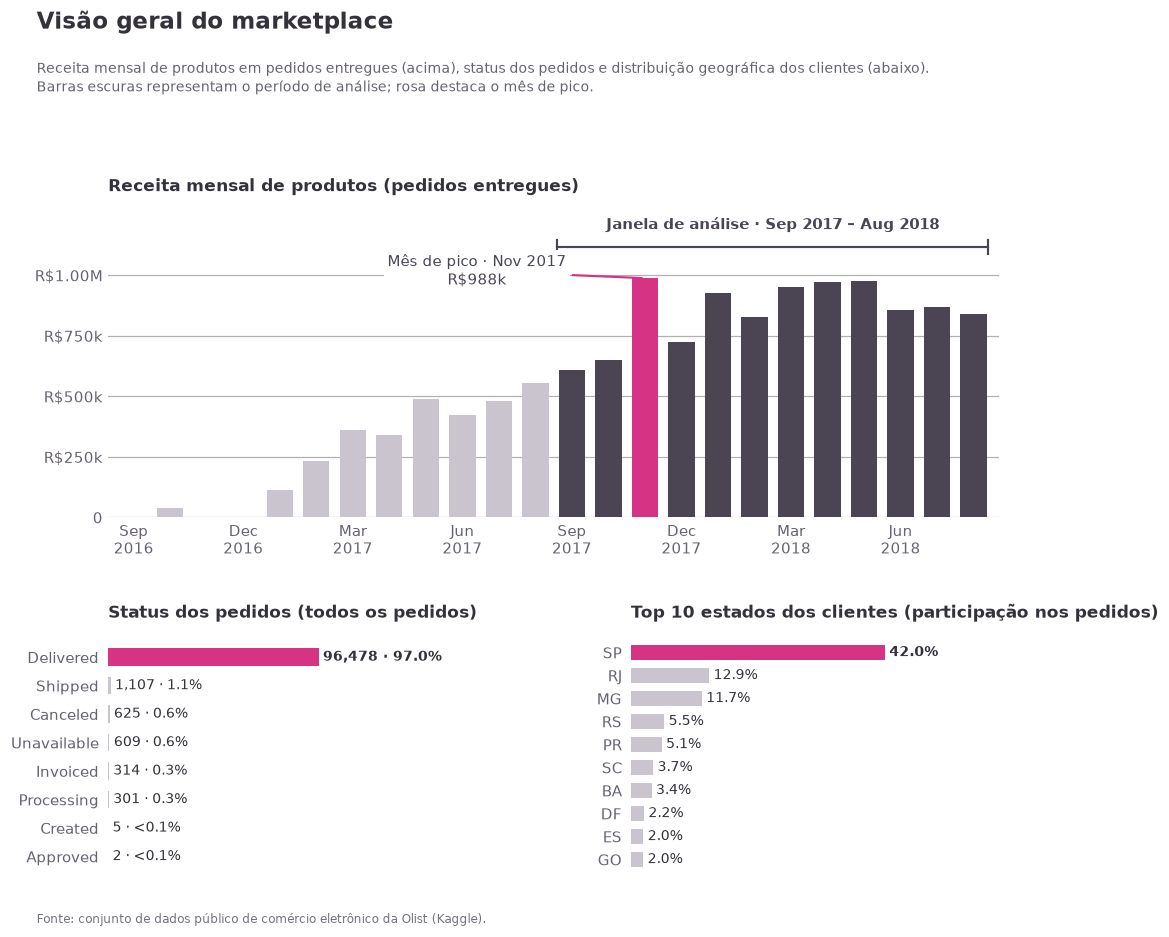

In [366]:
fig, gs = canvas(
    8.9,
    "Visão geral do marketplace",
    subtitulo=(
        "Receita mensal de produtos em pedidos entregues (acima), "
        "status dos pedidos e distribuição geográfica dos clientes (abaixo).\n"
        "Barras escuras representam o período de análise; rosa destaca o mês de pico."
    ),
    nrows=2,
    ncols=2,
    proporcoes_altura=[1.3, 1],
    margem_esquerda=1.45,
    margem_direita=0.45,
    espaco_vertical=0.42,
    espaco_horizontal=0.42
)

# Superior: receita mensal de produtos, ocupando toda a largura ----------------
ax = fig.add_subplot(gs[0, :])

x = np.arange(len(vendas_mensais))

cores = [
    PINK if p == mes_pico else (NIGHT if dentro else MIST)
    for p, dentro in zip(vendas_mensais.index, mes_na_janela)
]

ax.bar(x, vendas_mensais["receita_produtos"], width=0.72, color=cores, zorder=3)

valor_maximo = vendas_mensais["receita_produtos"].max()

ax.set_ylim(0, valor_maximo * 1.30)
ax.set_yticks(np.arange(0, valor_maximo * 1.06, 250_000))
ax.set_yticklabels([
    brl(v) if v else "0" for v in ax.get_yticks()
])

ax.yaxis.grid(True, zorder=0)
ax.tick_params(axis="y", length=0)

ax.set_xticks(x[::3])
ax.set_xticklabels([
    f"{p.start_time:%b}\n{p.start_time:%Y}"
    for p in vendas_mensais.index[::3]
], fontsize=9.5)

ax.tick_params(axis="x", length=0, pad=4)
ax.set_xlim(-0.7, len(vendas_mensais) - 0.3)

ax.set_title("Receita mensal de produtos (pedidos entregues)")

inicio_janela, fim_janela = [
    i for i, dentro in enumerate(mes_na_janela) if dentro
][0], [
    i for i, dentro in enumerate(mes_na_janela) if dentro
][-1]

ax.plot(
    [inicio_janela - 0.4, fim_janela + 0.4],
    [valor_maximo * 1.13] * 2,
    color=NIGHT,
    lw=1.4
)

for xx in (inicio_janela - 0.4, fim_janela + 0.4):
    ax.plot(
        [xx, xx],
        [valor_maximo * 1.10, valor_maximo * 1.16],
        color=NIGHT,
        lw=1.4
    )

ax.text(
    (inicio_janela + fim_janela) / 2,
    valor_maximo * 1.19,
    f"Janela de análise · {ROTULO_JANELA}",
    ha="center",
    va="bottom",
    fontsize=10,
    color=NIGHT,
    fontweight="bold"
)

indice_pico = list(vendas_mensais.index).index(mes_pico)

ax.annotate(
    f"Mês de pico · {mes_pico.start_time:%b %Y}\n"
    f"{brl(vendas_mensais.loc[mes_pico, 'receita_produtos'])}",
    xy=(indice_pico, vendas_mensais.loc[mes_pico, "receita_produtos"]),
    xytext=(indice_pico - 4.6, valor_maximo * 1.03),
    fontsize=9.5,
    color=NIGHT,
    ha="center",
    va="center",
    bbox=dict(facecolor=PAPER, edgecolor="none", pad=2),
    arrowprops=dict(
        arrowstyle="-",
        color=PINK,
        lw=1.4,
        shrinkB=2
    )
)


# Inferior esquerdo: status dos pedidos ----------------------------------------
ax = fig.add_subplot(gs[1, 0])

ranking_de_barras(
    ax,
    [s.title() for s in contagem_status.index],
    contagem_status.values,
    [
        f"{num(v)} · {pct(v / contagem_status.sum())}"
        for v in contagem_status.values
    ],
    destaques=(0,),
    margem=0.75
)

ax.set_title("Status dos pedidos (todos os pedidos)")


# Inferior direito: estados dos clientes ---------------------------------------
ax = fig.add_subplot(gs[1, 1])

ranking_de_barras(
    ax,
    list(participacao_estados.index),
    participacao_estados.values,
    [pct(v) for v in participacao_estados.values],
    destaques=(0,),
    margem=0.45
)

ax.set_title(f"Top {TOP_N} estados dos clientes (participação nos pedidos)")

show(fig, "01_marketplace_overview")

In [367]:
achado(
    f"{hl(pct(contagem_status['delivered'] / contagem_status.sum()))} de todos os pedidos estão com status de "
    f"<code>delivered</code> (entregues), portanto, restringir a análise de receita aos pedidos entregues "
    f"descarta uma parcela pequena do volume total.",

    f"A receita mensal de produtos atinge seu pico em "
    f"{hl(f'{mes_pico.start_time:%b %Y}')} "
    f"({brl(vendas_mensais.loc[mes_pico, 'receita_produtos'])}). "
    f"O dia com maior número de pedidos foi {hl(f'{dia_mais_movimentado:%d %b %Y}')}, "
    f"com {hl(num(total_dia_movimentado))} pedidos entregues, em comparação à mediana de "
    f"{num(dia_tipico)} pedidos por dia dentro da janela de análise.",

    f"Clientes de {hl(participacao_estados.index[0])} realizaram {hl(pct(participacao_estados.iloc[0]))} "
    f"de todos os pedidos; juntos, os três principais estados representam "
    f"{pct(participacao_estados.head(3).sum())} do total.",

    f"O conjunto de dados apresenta volume muito baixo nos primeiros meses "
    f"(a partir de {vendas_mensais.index.min().start_time:%b %Y}); o primeiro mês com "
    f"500 ou mais pedidos entregues foi "
    f"{vendas_mensais.index[(vendas_mensais['pedidos'] >= 500).argmax()].start_time:%b %Y}.",

    f"{hl(pct(participacao_estado_vendedores.iloc[0]))} dos vendedores ativos na janela de análise "
    f"estão localizados em {hl(participacao_estado_vendedores.index[0])}, "
    f"estado que também representa {pct(receita_por_estado_vendedor.iloc[0])} "
    f"da receita com produtos.",

    title="Principais achados · perfil do marketplace",
)

**Principais achados · perfil do marketplace**
- 97.0% de todos os pedidos estão com status de delivered (entregues), portanto, restringir a análise de receita aos pedidos entregues descarta uma parcela pequena do volume total.
- A receita mensal de produtos atinge seu pico em Nov 2017 (R$988k). O dia com maior número de pedidos foi 24 Nov 2017, com 1,147 pedidos entregues, em comparação à mediana de 197 pedidos por dia dentro da janela de análise.
- Clientes de SP realizaram 42.0% de todos os pedidos; juntos, os três principais estados representam 66.6% do total.
- O conjunto de dados apresenta volume muito baixo nos primeiros meses (a partir de Sep 2016); o primeiro mês com 500 ou mais pedidos entregues foi Jan 2017.
- 59.5% dos vendedores ativos na janela de análise estão localizados em SP, estado que também representa 64.3% da receita com produtos.



**Interpretação.** O período de 12 meses está inteiramente na fase mais madura da série, depois do crescimento inicial, evitando que os poucos meses do começo distorçam a análise. O pico do fim de novembro de 2017 coincide com a Black Friday (24 de novembro de 2017); é uma interpretação plausível do calendário, não algo que os dados provem. A demanda e a oferta também estão concentradas geograficamente. Isso pode ser relevante para o frete, que possivelmente depende da distância, mas esta análise não testa essa relação.

## 5. Perguntas de negócio e principais resultados

Salvo indicação contrária, todos os gráficos desta seção consideram **pedidos entregues e comprados dentro do período de análise** e usam **receita com produtos**, sem frete. O rosa destaca a resposta direta à pergunta de cada gráfico.

In [368]:
receita_total, frete_total = vendas_janela["price"].sum(), vendas_janela["freight_value"].sum()

kpi_strip([
    ("Pedidos entregues", num(vendas_janela["order_id"].nunique()), ROTULO_JANELA, False),
    ("Vendedores ativos", num(vendas_janela["seller_id"].nunique()), "com ≥ 1 pedido entregue", False),
    ("Categorias", num(vendas_janela["category"].nunique()), f'incl. “{SEM_CATEGORIA}”', False),
    ("Receita com produtos", brl(receita_total), "sem incluir o frete", True),
    ("Participação do frete", pct(frete_total / (receita_total + frete_total)), "sobre produtos + frete", False),
])

,Metric,Value,Context
0,Pedidos entregues,"74,213",Sep 2017 – Aug 2018
1,Vendedores ativos,"2,612",com ≥ 1 pedido entregue
2,Categorias,74,incl. “Sem categoria”
3,Receita com produtos,R$10.19M,sem incluir o frete
4,Participação do frete,14.4%,sobre produtos + frete


### 5.1 Categorias de produtos

**Análise:** receita com produtos por categoria, em ordem decrescente. Os painéis à direita mostram o **frete como proporção do preço + frete** para as mesmas categorias. Isso responde a uma pergunta complementar: incluir o frete mudaria a interpretação? Os rankings de maior e menor receita têm escalas muito diferentes, por isso cada um usa seu próprio eixo.

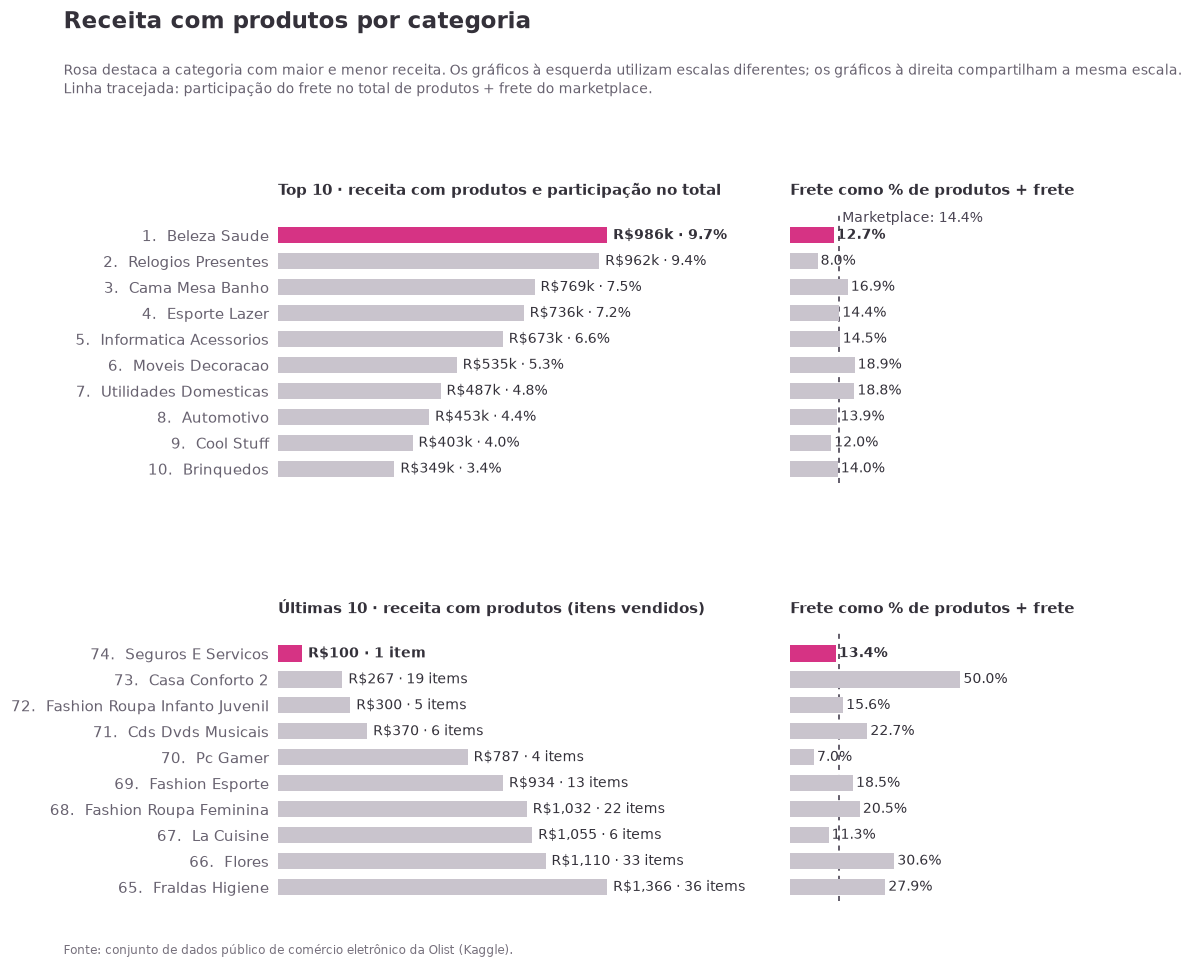

In [369]:
resumo_categorias = (
    vendas_janela.groupby("category")
    .agg(
        receita_produtos=("price", "sum"),
        frete=("freight_value", "sum"),
        itens=("order_id", "size"),
        pedidos=("order_id", "nunique")
    )
)

resumo_categorias["total_itens"] = (
    resumo_categorias["receita_produtos"] + resumo_categorias["frete"]
)

resumo_categorias["participacao_frete"] = (
    resumo_categorias["frete"] / resumo_categorias["total_itens"]
)

resumo_categorias["participacao_receita"] = (
    resumo_categorias["receita_produtos"]
    / resumo_categorias["receita_produtos"].sum()
)

resumo_categorias = resumo_categorias.sort_values(
    "receita_produtos", ascending=False, kind="stable"
)

resumo_categorias["posicao"] = np.arange(
    1, len(resumo_categorias) + 1
)

resumo_categorias["posicao_com_frete"] = (
    resumo_categorias["total_itens"]
    .rank(ascending=False, method="first")
    .astype(int)
)

top_categorias = resumo_categorias.head(TOP_N)
ultimas_categorias = resumo_categorias.tail(TOP_N).iloc[::-1]

participacao_frete_mercado = (
    resumo_categorias["frete"].sum()
    / resumo_categorias["total_itens"].sum()
)

frete_maximo = max(
    top_categorias["participacao_frete"].max(),
    ultimas_categorias["participacao_frete"].max()
) * 1.45


fig, gs = canvas(
    9.2,
    "Receita com produtos por categoria",
    subtitulo=(
        "Rosa destaca a categoria com maior e menor receita. "
        "Os gráficos à esquerda utilizam escalas diferentes; "
        "os gráficos à direita compartilham a mesma escala.\n"
        "Linha tracejada: participação do frete no total de produtos + frete do marketplace."
    ),
    nrows=2,
    ncols=2,
    proporcoes_largura=[2, 1],
    margem_esquerda=2.75,
    espaco_vertical=0.55,
    espaco_horizontal=0.05
)


for linha, (quadro, legenda, funcao_texto) in enumerate([
    (
        top_categorias,
        f"Top {TOP_N} · receita com produtos e participação no total",
        lambda r: f"{brl(r['receita_produtos'])} · {pct(r['participacao_receita'])}"
    ),
    (
        ultimas_categorias,
        f"Últimas {TOP_N} · receita com produtos (itens vendidos)",
        lambda r: (
            f"{brl(r['receita_produtos'])} · {num(r['itens'])} "
            f"item{'s' if r['itens'] != 1 else ''}"
        )
    ),
]):
    ax = fig.add_subplot(gs[linha, 0])

    ranking_de_barras(
        ax,
        [
            f"{int(r['posicao'])}.  {nome}"
            for nome, r in quadro.iterrows()
        ],
        quadro["receita_produtos"].values,
        [
            funcao_texto(r)
            for _, r in quadro.iterrows()
        ],
        destaques=(0,),
        margem=0.5
    )

    ax.set_title(legenda, pad=12, fontsize=10)

    ax = fig.add_subplot(gs[linha, 1])

    ranking_de_barras(
        ax,
        [],
        quadro["participacao_frete"].values,
        [
            pct(v)
            for v in quadro["participacao_frete"].values
        ],
        destaques=(0,),
        mostrar_rotulos=False,
        limite_x=frete_maximo
    )

    ax.axvline(
        participacao_frete_mercado,
        color=NIGHT,
        lw=1.1,
        ls=(0, (3, 3)),
        zorder=2
    )

    ax.set_title(
        "Frete como % de produtos + frete",
        pad=12,
        fontsize=10
    )

    if linha == 0:
        ax.text(
            participacao_frete_mercado + frete_maximo * 0.012,
            -0.66,
            f"Marketplace: {pct(participacao_frete_mercado)}",
            fontsize=9,
            color=NIGHT,
            va="center"
        )

show(fig, "02_category_revenue")

In [370]:
categoria_sem_classificacao = (
    resumo_categorias.loc[SEM_CATEGORIA]
    if SEM_CATEGORIA in resumo_categorias.index
    else None
)

categorias_com_posicao_alterada = int(
    (top_categorias["posicao"] != top_categorias["posicao_com_frete"]).sum()
)

achado(
    f"{hl(top_categorias.index[0])} lidera com "
    f"{hl(brl(top_categorias.iloc[0]['receita_produtos']))} "
    f"({pct(top_categorias.iloc[0]['participacao_receita'])} da receita com produtos); "
    f"as três principais categorias concentram {hl(pct(top_categorias.head(3)['participacao_receita'].sum()))}, "
    f"enquanto as {TOP_N} principais representam {pct(top_categorias['participacao_receita'].sum())}.",

    f"{hl(ultimas_categorias.index[0])} apresenta a menor receita, com "
    f"{hl(brl(ultimas_categorias.iloc[0]['receita_produtos']))} provenientes de "
    f"{num(ultimas_categorias.iloc[0]['itens'])} "
    f"item{'s' if ultimas_categorias.iloc[0]['itens'] != 1 else ''}; "
    f"as {TOP_N} categorias com menor receita somam apenas "
    f"{brl(ultimas_categorias['receita_produtos'].sum())}.",

    f"O frete representa {pct(participacao_frete_mercado)} do total de produtos + frete no marketplace. "
    f"Entre as {TOP_N} principais categorias, essa participação varia de "
    f"{pct(top_categorias['participacao_frete'].min())} a "
    f"{pct(top_categorias['participacao_frete'].max())}.",

    f"Classificar as categorias pelo valor de produtos + frete, em vez de apenas pela receita com produtos, "
    f"altera a posição de {hl(str(categorias_com_posicao_alterada))} "
    f"das {TOP_N} principais categorias."

    + (
        f" “{SEM_CATEGORIA}” (dados de categoria ausentes) ocuparia a "
        f"{int(categoria_sem_classificacao['posicao'])}ª posição, com "
        f"{brl(categoria_sem_classificacao['receita_produtos'])}."
        if categoria_sem_classificacao is not None else ""
    ),

    title="Principal resultado · categorias",
)


categorias_com_mudanca = resumo_categorias[
    (resumo_categorias["posicao"] != resumo_categorias["posicao_com_frete"]) &
    (
        (resumo_categorias["posicao"] <= TOP_N) |
        (resumo_categorias["posicao"] > len(resumo_categorias) - TOP_N)
    )
]

if len(categorias_com_mudanca):
    html_table(
        pd.DataFrame({
            "Categoria": categorias_com_mudanca.index,
            "Posição por receita com produtos": categorias_com_mudanca["posicao"].astype(int).values,
            "Posição por produtos + frete": categorias_com_mudanca["posicao_com_frete"].values
        }),
        caption="Categorias entre as maiores ou menores receitas cuja posição muda ao incluir o frete",
        align={
            "Posição por receita com produtos": "right",
            "Posição por produtos + frete": "right"
        },
        font_size=12
    )

**Principal resultado · categorias**
- Beleza Saude lidera com R$986k (9.7% da receita com produtos); as três principais categorias concentram 26.7%, enquanto as 10 principais representam 62.4%.
- Seguros E Servicos apresenta a menor receita, com R$100 provenientes de 1 item; as 10 categorias com menor receita somam apenas R$7,321.
- O frete representa 14.4% do total de produtos + frete no marketplace. Entre as 10 principais categorias, essa participação varia de 8.0% a 18.9%.
- Classificar as categorias pelo valor de produtos + frete, em vez de apenas pela receita com produtos, altera a posição de 0 das 10 principais categorias. “Sem categoria” (dados de categoria ausentes) ocuparia a 22ª posição, com R$122k.

Categorias entre as maiores ou menores receitas cuja posição muda ao incluir o frete


,Categoria,Posição por receita com produtos,Posição por produtos + frete
0,La Cuisine,67,68
1,Fashion Roupa Feminina,68,67
2,Cds Dvds Musicais,71,72
3,Fashion Roupa Infanto Juvenil,72,73
4,Casa Conforto 2,73,71


In [371]:
categorias_maior_frete = top_categorias.sort_values(
    "participacao_frete", ascending=False
).head(2)

nota(
    f"A resposta à pergunta “qual categoria vende mais?” "
    f"<b>não depende da inclusão do frete</b> entre as primeiras colocadas: "
    + (
        "a ordem das principais categorias é idêntica com ou sem o frete."
        if categorias_com_posicao_alterada == 0
        else f"apenas {categorias_com_posicao_alterada} das {TOP_N} principais categorias mudam de posição."
    )
    + " Onde o frete faz diferença é no <i>custo para o cliente</i>: "
    "sua participação varia bastante entre as categorias.",

    f"Entre as {TOP_N} principais categorias, "
    f"{esc(categorias_maior_frete.index[0])} e "
    f"{esc(categorias_maior_frete.index[1])} apresentam as maiores participações do frete "
    f"({pct(categorias_maior_frete.iloc[0]['participacao_frete'])} e "
    f"{pct(categorias_maior_frete.iloc[1]['participacao_frete'])}, respectivamente). "
    "O tamanho e o peso dos produtos são explicações plausíveis, "
    "mas isso é apenas uma hipótese: pesos e dimensões não foram analisados neste estudo.",

    "As categorias com menor receita dependem de uma quantidade reduzida de itens vendidos, "
    "portanto, um único pedido pode alterar sua posição no ranking. "
    "Uma receita baixa nesse contexto significa <i>poucos produtos vendidos</i> "
    "durante a janela de análise, e não necessariamente um desempenho ruim da categoria.",

    title="Interpretação · categorias",
)

Interpretação · categorias
- A resposta à pergunta “qual categoria vende mais?” não depende da inclusão do frete entre as primeiras colocadas: a ordem das principais categorias é idêntica com ou sem o frete. Onde o frete faz diferença é no custo para o cliente: sua participação varia bastante entre as categorias.
- Entre as 10 principais categorias, Moveis Decoracao e Utilidades Domesticas apresentam as maiores participações do frete (18.9% e 18.8%, respectivamente). O tamanho e o peso dos produtos são explicações plausíveis, mas isso é apenas uma hipótese: pesos e dimensões não foram analisados neste estudo.
- As categorias com menor receita dependem de uma quantidade reduzida de itens vendidos, portanto, um único pedido pode alterar sua posição no ranking. Uma receita baixa nesse contexto significa poucos produtos vendidos durante a janela de análise, e não necessariamente um desempenho ruim da categoria.



### 5.2 Vendedores com maior receita

**Análise:** vendedores ordenados pela receita com produtos. O gráfico ao lado mostra o **valor médio por pedido** dos mesmos vendedores, pois um vendedor pode chegar ao topo pelo volume de pedidos, por produtos mais caros ou por ambos. Os IDs dos vendedores são códigos anonimizados; os seis primeiros caracteres e o estado ajudam a identificá-los no gráfico.

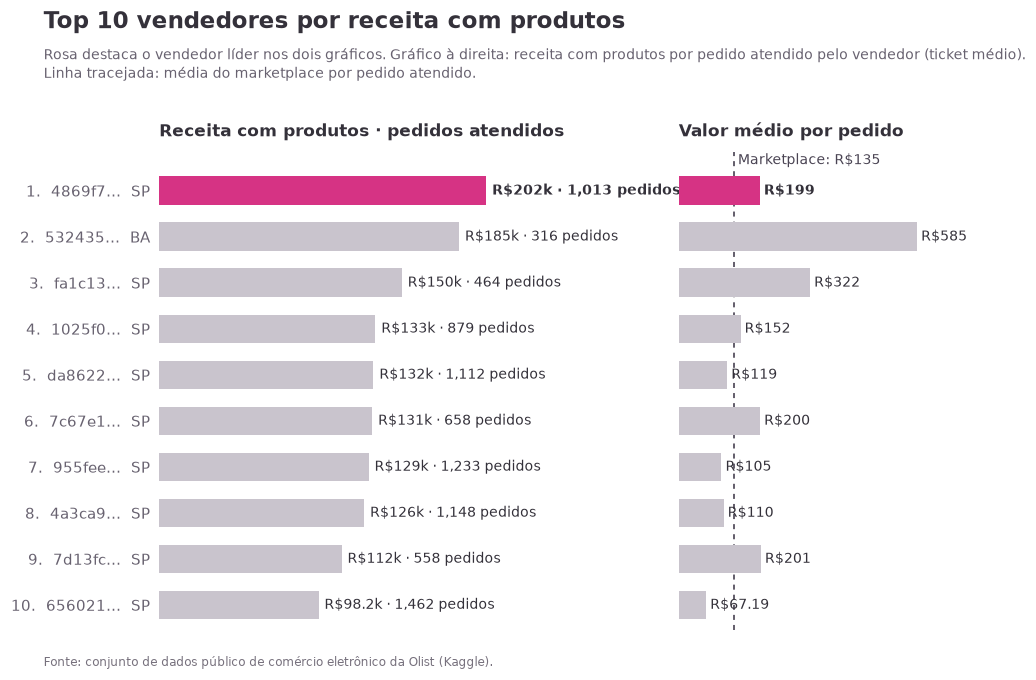

In [372]:
resumo_vendedores = (
    vendas_janela.groupby("seller_id")
    .agg(
        receita_produtos=("price", "sum"),
        frete=("freight_value", "sum"),
        pedidos=("order_id", "nunique"),
        itens=("order_id", "size"),
        estado=("seller_state", "first")
    )
)

resumo_vendedores["ticket_medio"] = (
    resumo_vendedores["receita_produtos"] / resumo_vendedores["pedidos"]
)

resumo_vendedores["participacao_receita"] = (
    resumo_vendedores["receita_produtos"]
    / resumo_vendedores["receita_produtos"].sum()
)

resumo_vendedores = (
    resumo_vendedores.reset_index()
    .sort_values(
        ["receita_produtos", "seller_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

resumo_vendedores["posicao"] = resumo_vendedores.index + 1

resumo_vendedores["rotulo"] = (
    resumo_vendedores["seller_id"].str.slice(0, 6)
    + "…  "
    + resumo_vendedores["estado"]
)

principais_vendedores = resumo_vendedores.head(TOP_N)

ticket_medio_mercado = (
    resumo_vendedores["receita_produtos"].sum()
    / resumo_vendedores["pedidos"].sum()
)


fig, gs = canvas(
    6.4,
    f"Top {TOP_N} vendedores por receita com produtos",
    subtitulo=(
        "Rosa destaca o vendedor líder nos dois gráficos. "
        "Gráfico à direita: receita com produtos por pedido atendido pelo vendedor (ticket médio).\n"
        "Linha tracejada: média do marketplace por pedido atendido."
    ),
    nrows=1,
    ncols=2,
    proporcoes_largura=[1.45, 1],
    margem_esquerda=1.85,
    espaco_horizontal=0.07
)


ax = fig.add_subplot(gs[0, 0])

ranking_de_barras(
    ax,
    [
        f"{r.posicao}.  {r.rotulo}"
        for r in principais_vendedores.itertuples()
    ],
    principais_vendedores["receita_produtos"].values,
    [
        f"{brl(r.receita_produtos)} · {num(r.pedidos)} pedidos"
        for r in principais_vendedores.itertuples()
    ],
    destaques=(0,),
    margem=0.50
)

ax.set_title("Receita com produtos · pedidos atendidos")


ax = fig.add_subplot(gs[0, 1])

limite_ticket_medio = (
    principais_vendedores["ticket_medio"].max() * 1.42
)

ranking_de_barras(
    ax,
    [],
    principais_vendedores["ticket_medio"].values,
    [
        brl(v)
        for v in principais_vendedores["ticket_medio"].values
    ],
    destaques=(0,),
    mostrar_rotulos=False,
    limite_x=limite_ticket_medio
)

ax.axvline(
    ticket_medio_mercado,
    color=NIGHT,
    lw=1.1,
    ls=(0, (3, 3)),
    zorder=2
)

ax.text(
    ticket_medio_mercado + limite_ticket_medio * 0.012,
    -0.66,
    f"Marketplace: {brl(ticket_medio_mercado)}",
    fontsize=9,
    color=NIGHT,
    va="center"
)

ax.set_title("Valor médio por pedido")

show(fig, "03_top_sellers")

In [373]:
lider = principais_vendedores.iloc[0]
segundo_colocado = principais_vendedores.iloc[1]
maior_ticket_medio = principais_vendedores.sort_values("ticket_medio", ascending=False).iloc[0]
maior_numero_pedidos = principais_vendedores.sort_values("pedidos", ascending=False).iloc[0]

achado(
    f"O vendedor {hl(lider['seller_id'][:6] + '…')} ({esc(lider['estado'])}) lidera com {hl(brl(lider['receita_produtos']))} em receita com produtos, provenientes de {num(lider['pedidos'])} pedidos "
    f"(ticket médio de {brl(lider['ticket_medio'])}). Isso representa {hl(pct(lider['participacao_receita']))} de toda a receita com produtos.",
    f"Os {TOP_N} principais vendedores juntos representam {hl(pct(principais_vendedores['participacao_receita'].sum()))} da receita com produtos, entre {num(len(resumo_vendedores))} vendedores ativos.",
    f"Entre os {TOP_N} principais, o ticket médio varia de {brl(principais_vendedores['ticket_medio'].min())} a {brl(principais_vendedores['ticket_medio'].max())}, "
    f"enquanto a média do marketplace é de {brl(ticket_medio_mercado)}.",
    title="Principal resultado · vendedores com maior receita",
)

mercado_fragmentado = (
    lider["participacao_receita"] < 0.05
    and principais_vendedores["participacao_receita"].sum() < 0.25
)

nota(
    (
        "Nenhum vendedor domina o mercado: o topo do marketplace é <b>fragmentado</b>. "
        "A participação do líder é pequena e os 10 principais vendedores concentram uma parcela modesta da receita total."
        if mercado_fragmentado
        else "A receita está <b>concentrada</b> nos principais vendedores: observe as participações apresentadas acima."
    ),
    f"Há mais de um caminho para o topo. O vendedor {esc(maior_ticket_medio['seller_id'][:6])}… tem o maior ticket médio "
    f"({brl(maior_ticket_medio['ticket_medio'])}, com {num(maior_ticket_medio['pedidos'])} pedidos), "
    f"enquanto {esc(maior_numero_pedidos['seller_id'][:6])}… atende ao maior número de pedidos "
    f"({num(maior_numero_pedidos['pedidos'])}), com ticket médio de {brl(maior_numero_pedidos['ticket_medio'])}. "
    "Apenas a posição no ranking de receita não revela essa diferença.",
    "A receita mede o valor das vendas, não a qualidade do vendedor: avaliações e desempenho das entregas não fazem parte deste ranking (veja as próximas análises).",
    title="Interpretação · vendedores com maior receita",
)

**Principal resultado · vendedores com maior receita**
- O vendedor 4869f7… (SP) lidera com R$202k em receita com produtos, provenientes de 1,013 pedidos (ticket médio de R$199). Isso representa 2.0% de toda a receita com produtos.
- Os 10 principais vendedores juntos representam 13.7% da receita com produtos, entre 2,612 vendedores ativos.
- Entre os 10 principais, o ticket médio varia de R$67.19 a R$585, enquanto a média do marketplace é de R$135.

Interpretação · vendedores com maior receita
- Nenhum vendedor domina o mercado: o topo do marketplace é fragmentado. A participação do líder é pequena e os 10 principais vendedores concentram uma parcela modesta da receita total.
- Há mais de um caminho para o topo. O vendedor 532435… tem o maior ticket médio (R$585, com 316 pedidos), enquanto 656021… atende ao maior número de pedidos (1,462), com ticket médio de R$67.19. Apenas a posição no ranking de receita não revela essa diferença.
- A receita mede o valor das vendas, não a qualidade

### 5.3 Vendedores com menor receita

**Análise:** os dez vendedores ativos com menor receita com produtos, comparados à distribuição de **todos os vendedores por quantidade de pedidos**. Um vendedor com apenas um pedido barato tende a aparecer no fim do ranking; por isso, a distribuição ao lado ajuda a contextualizar os dez últimos. São vendedores com menor receita, não “piores” vendedores: esta análise não mede qualidade.

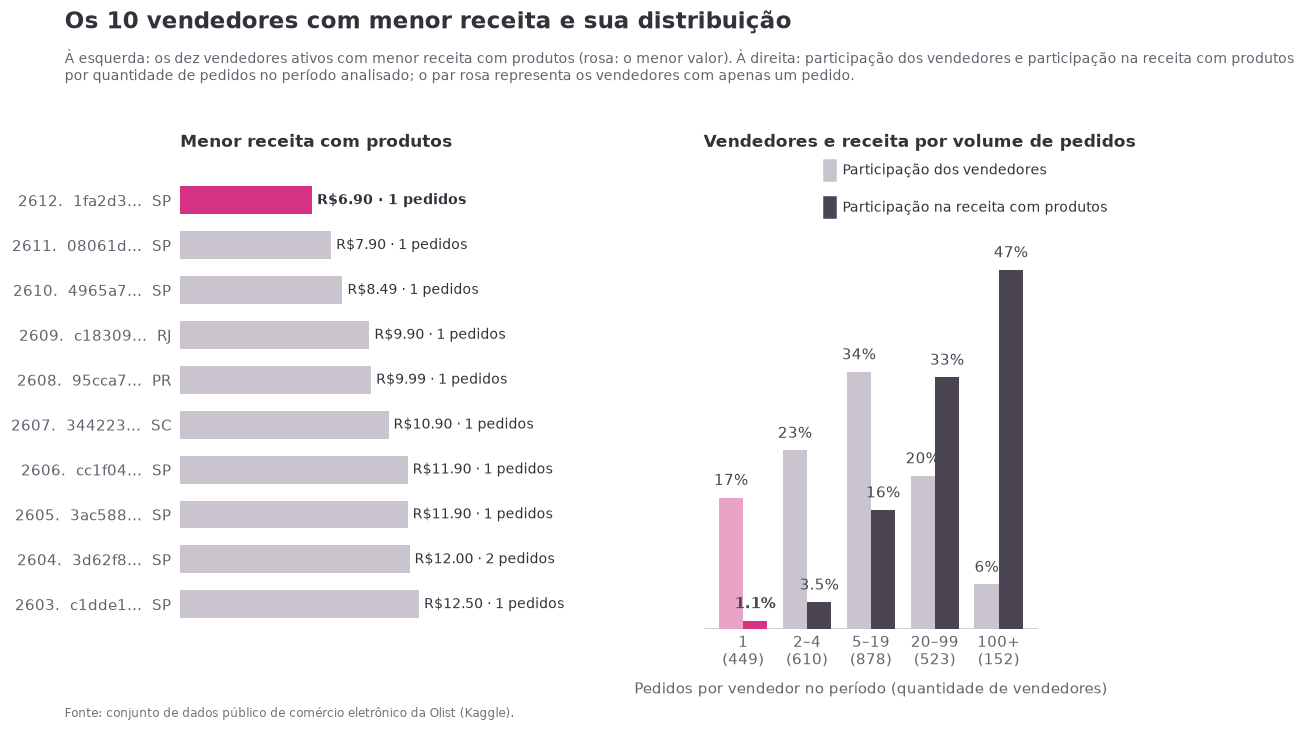

In [374]:
ultimos_vendedores = resumo_vendedores.tail(TOP_N).iloc[::-1]  # menor receita primeiro; empates mantêm a ordem do ranking

FAIXAS = [("1", 1, 1), ("2–4", 2, 4), ("5–19", 5, 19), ("20–99", 20, 99), ("100+", 100, np.inf)]
linhas_faixas = []

for nome, minimo, maximo in FAIXAS:
    mascara = resumo_vendedores["pedidos"].between(minimo, maximo)

    linhas_faixas.append({
        "faixa": nome,
        "vendedores": mascara.mean(),
        "receita": (
            resumo_vendedores.loc[mascara, "receita_produtos"].sum()
            / resumo_vendedores["receita_produtos"].sum()
        ),
        "quantidade": int(mascara.sum())
    })

faixas = pd.DataFrame(linhas_faixas)

fig, gs = canvas(
    6.9,
    f"Os {TOP_N} vendedores com menor receita e sua distribuição",
    subtitulo=(
        "À esquerda: os dez vendedores ativos com menor receita com produtos (rosa: o menor valor). "
        "À direita: participação dos vendedores e participação na receita com produtos\n"
        "por quantidade de pedidos no período analisado; o par rosa representa os vendedores com apenas um pedido."
    ),
    nrows=1,
    ncols=2,
    proporcoes_largura=[1.25, 1],
    margem_esquerda=1.85,
    espaco_horizontal=0.28,
    margem_rodape=1.0
)

ax = fig.add_subplot(gs[0, 0])

ranking_de_barras(
    ax,
    [
    f"{r.posicao}.  {r.rotulo}"
    for r in ultimos_vendedores.itertuples()],
    ultimos_vendedores["receita_produtos"].values,
    [
        f"{brl(r.receita_produtos)} · {num(r.pedidos)} pedidos"
        for r in ultimos_vendedores.itertuples()
    ],
    destaques=(0,),
    margem=0.75
)

ax.set_title("Menor receita com produtos")

ax = fig.add_subplot(gs[0, 1])

posicoes_x = np.arange(len(faixas))
largura = 0.38

ax.bar(
    posicoes_x - largura / 2,
    faixas["vendedores"],
    width=largura,
    color=[
        PINK_MUTED if i == 0 else MIST
        for i in range(len(faixas))
    ],
    zorder=3
)

ax.bar(
    posicoes_x + largura / 2,
    faixas["receita"],
    width=largura,
    color=[
        PINK if i == 0 else NIGHT
        for i in range(len(faixas))
    ],
    zorder=3
)

for i, r in faixas.iterrows():
    ax.text(
        i - largura / 2,
        r["vendedores"] + 0.012,
        pct(r["vendedores"], 0),
        ha="center",
        va="bottom",
        fontsize=9.5,
        color=NIGHT
    )

    ax.text(
        i + largura / 2,
        r["receita"] + 0.012,
        pct(r["receita"], 0 if r["receita"] >= 0.1 else 1),
        ha="center",
        va="bottom",
        fontsize=9.5,
        color=NIGHT,
        fontweight="bold" if i == 0 else "normal"
    )

ax.set_xticks(posicoes_x)

ax.set_xticklabels(
    [
        f"{faixa}\n({num(quantidade)})"
        for faixa, quantidade in zip(faixas["faixa"], faixas["quantidade"])
    ],
    fontsize=9.5
)

ax.set_xlabel(
    "Pedidos por vendedor no período (quantidade de vendedores)",
    fontsize=9.5,
    labelpad=8
)

ax.set_ylim(
    0,
    max(faixas["vendedores"].max(), faixas["receita"].max()) * 1.30
)

ax.yaxis.set_visible(False)
ax.tick_params(axis="x", length=0)
ax.axhline(0, color=MIST, lw=1)

adicionar_legenda(
    ax,
    [
        (MIST, "Participação dos vendedores"),
        (NIGHT, "Participação na receita com produtos")
    ],
    x=0.36,
    y=0.99,
    espacamento_vertical=0.08
)

ax.set_title("Vendedores e receita por volume de pedidos")

show(fig, "04_lowest_revenue_sellers")

In [375]:
faixa_unico_pedido = faixas.iloc[0]
faixa_maior_volume = faixas.iloc[-1]

achado(
    f"Os {TOP_N} vendedores com menor receita faturaram entre "
    f"{hl(brl(ultimos_vendedores['receita_produtos'].min()))} e "
    f"{hl(brl(ultimos_vendedores['receita_produtos'].max()))} cada; "
    f"{int((ultimos_vendedores['pedidos'] == 1).sum())} deles atenderam exatamente um pedido no período.",
    f"Vendedores com apenas um pedido representam {hl(pct(faixa_unico_pedido['vendedores']))} dos vendedores ativos, "
    f"mas respondem por apenas {hl(pct(faixa_unico_pedido['receita']))} da receita com produtos.",
    f"No outro extremo, os {num(faixa_maior_volume['quantidade'])} vendedores com "
    f"{faixa_maior_volume['faixa']} pedidos representam {pct(faixa_maior_volume['vendedores'])} dos vendedores "
    f"e {hl(pct(faixa_maior_volume['receita']))} da receita com produtos.",
    title="Principal resultado · vendedores com menor receita",
)

predominio_pedido_unico = (
    (ultimos_vendedores["pedidos"] == 1).mean() >= 0.5
)

nota(
    (
        "A parte inferior do ranking de receita é composta principalmente por vendedores com "
        "<b>atividade muito pequena e ocasional</b>, e não necessariamente por vendedores com baixo desempenho. "
        "O ranking mostra apenas o quanto esses vendedores venderam no período."
        if predominio_pedido_unico
        else "Os vendedores com menor receita não são, neste caso, apenas vendedores com um único pedido. "
        "Observe a quantidade de pedidos no gráfico antes de tirar conclusões."
    ),
    "Os dados não possuem a data de início de atividade dos vendedores nem um indicador de inatividade. "
    "Portanto, não é possível determinar se esses vendedores são novos, ocasionais ou estão encerrando suas atividades. "
    "Classificá-los como “piores vendedores” não teria fundamento: avaliar a qualidade dos vendedores exige dados "
    "sobre avaliações, cancelamentos e desempenho das entregas.",
    title="Interpretação · vendedores com menor receita",
)

**Principal resultado · vendedores com menor receita**
- Os 10 vendedores com menor receita faturaram entre R$6.90 e R$12.50 cada; 9 deles atenderam exatamente um pedido no período.
- Vendedores com apenas um pedido representam 17.2% dos vendedores ativos, mas respondem por apenas 1.1% da receita com produtos.
- No outro extremo, os 152 vendedores com 100+ pedidos representam 5.8% dos vendedores e 47.0% da receita com produtos.

Interpretação · vendedores com menor receita
- A parte inferior do ranking de receita é composta principalmente por vendedores com atividade muito pequena e ocasional, e não necessariamente por vendedores com baixo desempenho. O ranking mostra apenas o quanto esses vendedores venderam no período.
- Os dados não possuem a data de início de atividade dos vendedores nem um indicador de inatividade. Portanto, não é possível determinar se esses vendedores são novos, ocasionais ou estão encerrando suas atividades. Classificá-los como “piores vendedores” não teria fun

### 5.4 Robustez: o que muda quando as definições mudam?

**Análise:** os mesmos rankings são recalculados com outras métricas de receita e períodos. A variante **A** é a análise principal. **B** inclui o frete. **C** define o período a partir da data de entrega mais recente (ver 3.3). **D** e **E** reproduzem uma versão anterior do projeto que multiplicava por `order_item_id`; aparecem apenas para quantificar o efeito desse erro e **não são medidas válidas de receita** (3.4).

In [376]:
base_antiga = vendas.loc[
    vendas["order_purchase_timestamp"] > corte_anteriores
]

VARIANTES = [
    ("A · Análise principal", "price", ROTULO_JANELA, vendas_janela, lambda d: d["price"]),
    ("B · Inclusão do frete", "price + freight", ROTULO_JANELA, vendas_janela, lambda d: d["price"] + d["freight_value"]),
    ("C · Janela baseada na última entrega", "price", f"compras após {corte_anteriores:%d %b %Y}", base_antiga, lambda d: d["price"]),
    ("D · Fórmula anterior, janela principal", "price × order_item_id", ROTULO_JANELA, vendas_janela, lambda d: d["price"] * d["order_item_id"]),
    ("E · Método anterior (fórmula + janela)", "(price + freight) × order_item_id", f"compras após {corte_anteriores:%d %b %Y}", base_antiga,
     lambda d: (d["price"] + d["freight_value"]) * d["order_item_id"]),
]


def calcular_rankings(base, funcao_valor):
    valor = funcao_valor(base)

    por_categoria = (
        valor.groupby(base["category"])
        .sum()
        .sort_values(ascending=False, kind="stable")
    )

    por_vendedor = (
        valor.groupby(base["seller_id"])
        .sum()
        .sort_values(ascending=False, kind="stable")
    )

    return valor.sum(), por_categoria, por_vendedor


resultados = [
    (nome, metrica, janela, *calcular_rankings(base, funcao))
    for nome, metrica, janela, base, funcao in VARIANTES
]

_, _, _, _, categoria_referencia, vendedor_referencia = resultados[0]

estado_vendedor = sellers.set_index("seller_id")["seller_state"]

linhas, indices_diferentes = [], []

for i, (nome, metrica, janela, total, por_categoria, por_vendedor) in enumerate(resultados):

    mesmo_lider = por_vendedor.index[0] == vendedor_referencia.index[0]

    if not mesmo_lider:
        indices_diferentes.append(i)

    linhas.append({
        "Variante": nome,
        "Métrica de receita": metrica,
        "Período": janela,
        "Total": brl(total),
        "Categoria em 1º lugar": por_categoria.index[0],
        "Vendedor em 1º lugar": (
            f"{por_vendedor.index[0][:6]}… "
            f"{estado_vendedor[por_vendedor.index[0]]}"
        ),
        "Mesmo vendedor em 1º lugar que A?": (
            "Sim" if mesmo_lider else "NÃO"
        ),
        "Vendedores do Top 10 em comum com A": (
            f"{len(set(por_vendedor.index[:TOP_N]) & set(vendedor_referencia.index[:TOP_N]))} / {TOP_N}"
        ),
        "Categorias do Top 10 em comum com A": (
            f"{len(set(por_categoria.index[:TOP_N]) & set(categoria_referencia.index[:TOP_N]))} / {TOP_N}"
        ),
    })

html_table(
    pd.DataFrame(linhas),
    caption="Rankings com definições alternativas (linhas destacadas indicam outro vendedor em 1º lugar)",
    highlight=indices_diferentes,
    align={"Total": "right"},
    font_size=11.5
)

Rankings com definições alternativas (linhas destacadas indicam outro vendedor em 1º lugar)


,Variante,Métrica de receita,Período,Total,Categoria em 1º lugar,Vendedor em 1º lugar,Mesmo vendedor em 1º lugar que A?,Vendedores do Top 10 em comum com A,Categorias do Top 10 em comum com A
0,A · Análise principal,price,Sep 2017 – Aug 2018,R$10.19M,Beleza Saude,4869f7… SP,Sim,10 / 10,10 / 10
1,B · Inclusão do frete,price + freight,Sep 2017 – Aug 2018,R$11.90M,Beleza Saude,4869f7… SP,Sim,9 / 10,10 / 10
2,C · Janela baseada na última entrega,price,compras após 17 Oct 2017,R$9.23M,Beleza Saude,4869f7… SP,Sim,10 / 10,9 / 10
3,"D · Fórmula anterior, janela principal",price × order_item_id,Sep 2017 – Aug 2018,R$11.61M,Beleza Saude,7c67e1… SP,NÃO,9 / 10,9 / 10
4,E · Método anterior (fórmula + janela),(price + freight) × order_item_id,compras após 17 Oct 2017,R$12.32M,Beleza Saude,7c67e1… SP,NÃO,9 / 10,9 / 10


In [377]:
lideres_categorias = {r[0]: r[4].index[0] for r in resultados}
vendedores_compartilhados = [len(set(r[5].index[:TOP_N]) & set(vendedor_referencia.index[:TOP_N])) for r in resultados[1:]]
apenas_variantes_antigas = set(indices_diferentes) <= {3, 4}
resultados_estaveis = all(resultados[i][5].index[0] == vendedor_referencia.index[0] and resultados[i][4].index[0] == categoria_referencia.index[0] for i in (1, 2))

achado(
    (f"A categoria em 1º lugar é {hl(categoria_referencia.index[0])} nas {len(resultados)} definições." if len(set(lideres_categorias.values())) == 1 else
     f"A categoria em 1º lugar não é a mesma em todas as definições: {', '.join(sorted(set(lideres_categorias.values())))}."),
    f"O vendedor em 1º lugar muda em {hl(str(len(indices_diferentes)))} das {len(resultados) - 1} alternativas"
    + (": " + ", ".join(resultados[i][0].split(' · ')[0] for i in indices_diferentes) + ". " if indices_diferentes else ". ")
    + ("Ambas utilizam a multiplicação por <code>order_item_id</code>, que superestima a receita de vendedores que comercializam várias unidades por pedido." if indices_diferentes and apenas_variantes_antigas else ""),
    f"As duas alternativas <i>válidas</i> (B: incluir frete; C: janela mais recente) compartilham {hl(str(min(vendedores_compartilhados[:2])) + '–' + str(max(vendedores_compartilhados[:2])))} "
    f"dos {TOP_N} principais vendedores com a análise principal" + (" e mantêm o mesmo vendedor e a mesma categoria em 1º lugar." if resultados_estaveis else "; o vendedor ou a categoria em 1º lugar é diferente. Consulte a tabela."),
    title="Principal resultado · robustez",
)

nota(
    ("As principais conclusões (categoria líder e vendedor líder) permanecem válidas diante das mudanças legítimas de definição. O que muda é a <b>ordem dentro do top 10</b>; "
     "portanto, as posições de 2º a 10º lugar devem ser interpretadas em conjunto, e não como classificações exatas." if resultados_estaveis else
     "As principais conclusões são <b>sensíveis</b> às definições testadas; trate os rankings como provisórios até que a escolha da definição seja justificada."),
    "O erro de multiplicação tem maior impacto justamente onde é menos perceptível: ele pode alterar silenciosamente o vendedor em 1º lugar. "
    "Por isso, a Seção 3.4 testa o significado de <code>order_item_id</code>, em vez de simplesmente assumir sua interpretação.",
    title="Interpretação · robustez",
)

**Principal resultado · robustez**
- A categoria em 1º lugar é Beleza Saude nas 5 definições.
- O vendedor em 1º lugar muda em 2 das 4 alternativas: D, E. Ambas utilizam a multiplicação por order_item_id, que superestima a receita de vendedores que comercializam várias unidades por pedido.
- As duas alternativas válidas (B: incluir frete; C: janela mais recente) compartilham 9–10 dos 10 principais vendedores com a análise principal e mantêm o mesmo vendedor e a mesma categoria em 1º lugar.

Interpretação · robustez
- As principais conclusões (categoria líder e vendedor líder) permanecem válidas diante das mudanças legítimas de definição. O que muda é a ordem dentro do top 10; portanto, as posições de 2º a 10º lugar devem ser interpretadas em conjunto, e não como classificações exatas.
- O erro de multiplicação tem maior impacto justamente onde é menos perceptível: ele pode alterar silenciosamente o vendedor em 1º lugar. Por isso, a Seção 3.4 testa o significado de order_item_id, em vez

## 6. Conclusões, limitações e próximos passos

### 6.1 Resumo dos resultados

In [378]:
%whos


Variable                          Type         Data/Info
--------------------------------------------------------
CLOUD                             str          #F5F2F5
DATA_DIR                          PosixPath    dataset
DATE_COLUMNS                      dict         n=3
FAIXAS                            list         n=5
FIG_DIR                           PosixPath    imagens
FIM_JANELA                        Timestamp    2018-09-01 00:00:00
FOG                               str          #E8E4E9
FONT                              str          DejaVu Sans
GRAIN                             dict         n=9
INICIO_JANELA                     Timestamp    2017-09-01 00:00:00
INK                               str          #34313A
KEYS                              dict         n=9
MIST                              str          #C9C4CD
NIGHT                             str          #4A4453
NOTA_FONTE                        str          Fonte: conjunto de dados <...>. R$ = reais brasileiros.
P

In [379]:
print("LIDER:")
display(lider)

print("\nCOLUNAS DE PRINCIPAIS_VENDEDORES:")
print(principais_vendedores.columns.tolist())

print("\nPRIMEIRA LINHA:")
display(principais_vendedores.head(1))

LIDER:


seller_id               4869f7a5dfa277a7dca6462dcf3b52b2
receita_produtos                                201576.0
frete                                           18233.55
pedidos                                             1013
itens                                               1035
estado                                                SP
ticket_medio                                  198.989141
participacao_receita                            0.019786
posicao                                                1
rotulo                                       4869f7…  SP
Name: 0, dtype: object


COLUNAS DE PRINCIPAIS_VENDEDORES:
['seller_id', 'receita_produtos', 'frete', 'pedidos', 'itens', 'estado', 'ticket_medio', 'participacao_receita', 'posicao', 'rotulo']

PRIMEIRA LINHA:


,seller_id,receita_produtos,frete,pedidos,itens,estado,ticket_medio,participacao_receita,posicao,rotulo
0,4869f7a5dfa277a7dca6462dcf3b52b2,201576.0,18233.55,1013,1035,SP,198.989141,0.019786,1,4869f7… SP


In [380]:
achado(
    f"<b>Q1 · Categorias:</b> \n {hl(lider_produtos.name)} gerou a maior receita com produtos ({brl(lider_produtos['receita_produtos'])}) em {ROTULO_JANELA}; "
    f"a menor receita foi registrada por {hl(ultimas_categorias.index[0])} ({brl(ultimas_categorias.iloc[0]['receita_produtos'])}).\n",
    
    f"<b>Q2 · Principais vendedores:</b> \n O vendedor {hl(lider['seller_id'][:6] + '…')} lidera com {brl(lider['receita_produtos'])}, mas representa apenas {pct(lider['participacao_receita'])} da receita com produtos; "
    f"os {TOP_N} principais vendedores concentram {pct(principais_vendedores['participacao_receita'].sum())}.\n",
    
    f"<b>Q3 · Vendedores com menor receita:</b> \n " + ("Esse grupo é composto principalmente por vendedores com apenas um pedido de baixo valor. " if predominio_pedido_unico else "") + 
    f"Vendedores com apenas um pedido representam {pct(faixa_unico_pedido['vendedores'])} dos vendedores e {pct(faixa_unico_pedido['receita'])} da receita.",
    ("<b>Robustez.</b> A categoria e o vendedor líderes permanecem os mesmos nas definições alternativas válidas."
     if resultados_estaveis else "<b>Robustez.</b> As principais conclusões são sensíveis às definições testadas (consulte a seção 5.4).")
    + (" A multiplicação anterior por <code>order_item_id</code> teria alterado o vendedor em 1º lugar." if indices_diferentes and apenas_variantes_antigas else ""),
    title="Resumo",
)

**Resumo**
- Q1 · Categorias: 
 11 gerou a maior receita com produtos (R$986k) em Sep 2017 – Aug 2018; a menor receita foi registrada por Seguros E Servicos (R$100).

- Q2 · Principais vendedores: 
 O vendedor 4869f7… lidera com R$202k, mas representa apenas 2.0% da receita com produtos; os 10 principais vendedores concentram 13.7%.

- Q3 · Vendedores com menor receita: 
 Esse grupo é composto principalmente por vendedores com apenas um pedido de baixo valor. Vendedores com apenas um pedido representam 17.2% dos vendedores e 1.1% da receita.
- Robustez. A categoria e o vendedor líderes permanecem os mesmos nas definições alternativas válidas. A multiplicação anterior por order_item_id teria alterado o vendedor em 1º lugar.



### 6.2 Limitações

- **Receita é o valor das vendas no marketplace, não a receita da empresa.** Inclui o preço dos produtos em pedidos entregues. Os dados não informam a comissão da Olist nem registram reembolsos ou devoluções após a entrega.
- **Um recorte, um período.** Os dados terminam no fim de agosto de 2018 e representam um marketplace ainda jovem; os padrões podem não se repetir em outros períodos ou canais. Os preços são nominais, sem ajuste pela inflação.
- **Somente pedidos entregues entram na análise.** Pedidos cancelados, indisponíveis e em trânsito são excluídos. Pedidos ainda em trânsito quando os dados foram extraídos não aparecem como vendas concluídas nas semanas finais.
- **Ranking de receita não mede desempenho.** Avaliações, cancelamentos e prazos de entrega não fazem parte do ranking; “menor receita” não significa “pior vendedor”.
- **As categorias dependem da qualidade dos dados dos produtos.** Alguns produtos não têm categoria e aparecem como “Sem categoria”; os nomes dependem do arquivo de tradução e de duas entradas manuais.
- **A análise é descritiva.** Não demonstra causas para diferenças na proporção de frete ou para o pico de novembro, por exemplo.
- **Ressalvas mantidas.** `review_id` não é único e a tabela de geolocalização contém muitas linhas exatamente duplicadas; nenhuma das duas situações é usada no cálculo da receita.

### 6.3 Próximos passos possíveis (não realizados neste notebook)

1. **Métricas de qualidade dos vendedores:** combinar notas de avaliação, taxas de cancelamento e entregas no prazo (data real versus estimada) com o ranking de receita, distinguindo vendedores grandes de vendedores bons.
2. **Sazonalidade:** comparar a receita mensal por categoria para verificar se as líderes são estáveis ou se o resultado é influenciado por períodos de pico, como novembro de 2017.
3. **Fatores associados ao frete:** relacionar o frete ao peso, às dimensões dos produtos e à distância entre vendedor e cliente (há uma tabela de geolocalização disponível).
4. **Comportamento dos clientes:** usar `customer_unique_id` para estudar compras recorrentes.
5. **Receita da Olist:** se uma taxa de comissão estiver disponível, estimar a receita do marketplace a partir das vendas dos lojistas.

### 6.4 Reprodutibilidade, fonte dos dados e licença

- **Dados:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle). Os dados brutos não estão incluídos neste projeto; confira a licença antes de reutilizar ou redistribuir.
- **Execução:** números, rótulos e destaques são calculados a partir dos dados durante a execução. Os gráficos são exportados para `figures/` (desative com `SAVE_FIGURES = False`).
- **Configuração:** consulte o README do projeto para ver as dependências e as instruções.

In [381]:
import sys
nota(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__} · matplotlib {mpl.__version__} · chart font: {FONT}.",
     title="Ambiente desta execução")

Ambiente desta execução
- Python 3.12.3 · pandas 3.0.5 · numpy 2.5.1 · matplotlib 3.11.0 · chart font: DejaVu Sans.

